#### Sparse reconstruction of the [15 × 716] LiDAR grid with a range-weighted penalty
#### Known obstacle map + UAV-relative geometry + causal time-step history

### 0. Required run configuration — entire-map temporal reconstruction

This is a separate copy of `train_sparse_reconstruction_single_episode_baseline.ipynb`.
The same 0–9 section sequence, cell roles, sparse encoder/U-Net, range-weighted loss,
AdamW/cosine loop, checkpoints, logs and result plots are retained. The baseline stays untouched. Resume utilities live in `scripts/carc/checkpoint_resume.py`.
**Run the cells in order. This notebook is prepared for you to train; it contains no trained outputs.**

The default corpus combines the existing audited 80 healthy-LiDAR MATLAB flights with
192 new kinematic trajectories. Synthetic starts and goals cover **North −5–40 m,
East −5–40 m, altitude 1–10 m** (NED Down −10 to −1 m), with obstacle clearance.
Synthetic labels come from the actual building map and recorded sensor mount/ray grid.
They are geometric simulations, not MATLAB closed-loop flight results.

**Runtime inputs:** supplied static obstacle centers/dimensions, estimated position,
velocity and attitude, mission goal, current available LiDAR and up to 16 causal history steps.
Map geometry remains available during deployment. Clean hidden scans, future states,
future goals and future LiDAR never enter reconstruction inputs. Pose noise/drift is enabled.
Repeated random outages, sector/beam loss, long blackouts and an entire flight with no
LiDAR from takeoff are included. Finite history cannot by itself recover indefinite
blackouts; the map and sufficiently accurate localization provide continuing geometry.

Whole trajectories are split 80/10/10 **before** history windows or faults are built.
Validation seeds are fixed; training fault/pose/noise histories change every epoch.
Test flights stay out of checkpoint selection. The best model is compared with a
map-only ray-casting baseline, including cold-start and longer-than-history blackouts.

Paths are detected from the cloned checkout on Windows or Linux. Start the kernel in
the checkout or its `notebooks` directory. Optional environment variables:
`ARES_REPO_ROOT` (checkout), `ARES_RUN_ROOT` (generated exports/cache/results),
`ARES_CACHE_ROOT` (synthetic cache override). On CARC use `/scratch1/awagh/ARES`
for the checkout and `/scratch1/awagh/ares-training` for `ARES_RUN_ROOT`.
See `docs/CARC_MAP_TEMPORAL.md` for `salloc` setup and the command-line launcher.
CUDA PyTorch >=2.5 is recommended. BF16 requires a
supported GPU (choose `fp16` otherwise). Scan caches need several GB of free disk;
generation prints progress and is reused by fingerprint. No raw data is overwritten.

This remains a **scan reconstructor**, not a trained navigation policy or a proof of
mission safety. Goal features describe the mission; they do not guarantee goal reaching.
Three UAVs can share weights and the map with isolated buffers using
`MultiUavReconstruction`; current peer positions/inter-UAV collision avoidance are outside
this static-map model. The existing single-episode MATLAB exporter cannot load this architecture.

In [ ]:
from pathlib import Path
from collections import OrderedDict, deque
from contextlib import nullcontext
import copy
import csv
import hashlib
import heapq
import json
import logging
import math
import os
import random
import sys
import time
from datetime import datetime, timezone
from types import SimpleNamespace
from time import perf_counter
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

MAX_RANGE = 7.0
N_EL, N_AZ = 15, 716
DATA_BUILDER_VERSION = "ares-known-map-temporal-v1"
SELECTION_METRICS = ("val_loss", "val_mse", "val_outage_mse", "val_blackout_mse")
INPUT_KEYS = ("ranges", "valid", "available", "states", "goals", "history",
              "present", "ages", "obstacles")
def find_repo_root(start=None):
    """Find a cloned checkout from its root/notebooks folder, or ARES_REPO_ROOT."""
    configured = os.environ.get("ARES_REPO_ROOT")
    origin = Path(configured or start or Path.cwd()).expanduser().resolve()
    candidates = [origin] if configured else [origin, *origin.parents]
    for candidate in candidates:
        if (candidate / "notebooks" / "train_sparse_reconstruction_map_temporal.ipynb").is_file():
            return candidate
    raise FileNotFoundError("Cannot locate ARES. Start the kernel in the cloned checkout or set ARES_REPO_ROOT.")


DEFAULT_REPO_ROOT = find_repo_root()
DEFAULT_RUN_ROOT = Path(os.environ.get("ARES_RUN_ROOT", DEFAULT_REPO_ROOT)).expanduser().resolve()
CONFIG = {
    "paths": {
        "repo_root": str(DEFAULT_REPO_ROOT),
        "output_root": str(DEFAULT_RUN_ROOT / "results" / "sparse_reconstruction_map_temporal"),
        "cache_root": str(Path(os.environ.get("ARES_CACHE_ROOT", DEFAULT_RUN_ROOT / "data" / "processed" / "map_temporal_lidar_v1")).expanduser().resolve()),
    },
    "run": {"name": "Map Temporal Sparsity Invariant CNN", "seed": 42},
    "data": {
        "batch_id": "c3eaab07-d882-4825-98a5-84c278cf8935",
        "train_fraction": 0.8, "val_fraction": 0.1, "test_fraction": 0.1,
        "split_policy": "whole_trajectory", "verify_hashes": True,
        "sample_period_s": 0.1, "history_steps": 16, "cache_trajectories": 3,
    },
    "map": {
        "north_bounds_m": [-5.0, 40.0], "east_bounds_m": [-5.0, 40.0],
        "altitude_bounds_m": [1.0, 10.0],
        "vehicle_radius_m": 0.1, "surface_clearance_m": 0.6,
    },
    "synthetic": {
        "trajectory_count": 192, "seed": 6841,
        "speed_mps": [0.7, 3.0], "minimum_start_goal_distance_m": 5.0,
        "near_obstacle_probability": 0.5, "near_obstacle_distance_m": [0.8, 6.0],
        "roll_pitch_limit_deg": 15.0, "max_frames_per_trajectory": 2400,
        "raycast_batch_size": 16,
    },
    "model": {
        "max_range": MAX_RANGE, "elevation_vectors": N_EL, "azimuth_vectors": N_AZ,
        "azimuth_degree": [-179.0, 179.0], "elevation_degree": [-15.0, 15.0],
        "degree_per_column": 358.0 / 715.0,
        "ring_channels": 7, "sector_bearing_deg": [-60.0, 60.0],
        "widths": [32, 64, 96], "kernel": 7, "state_hidden": 128,
        "history_hidden": 128, "history_channels": 16, "obstacle_hidden": 32,
        "history_grid": [3, 90], "state_features": 18,
        "position_scale_m": 45.0, "velocity_scale_mps": 5.0,
        "residual_limit_m": 7.0, "obstacle_width_m": 3.0,
        "mounting_translation_body_m": [0.0, 0.0, -0.4],
        "sensor_to_body_rotation": [[1., 0., 0.], [0., -1., 0.], [0., 0., -1.]],
    },
    "masking": {
        "partial_probability": 0.7, "blocks_per_scan": [1, 6],
        "obstacle_distance_m": [0.5, 7.0], "beam_dropout_fraction": [0.0, 0.15],
        "blackout_start_probability": 0.035, "blackout_duration_frames": [2, 80],
        "long_blackout_frames": 100,
        "training_profiles": {"mixed": 0.55, "healthy": 0.1, "blackout_burst": 0.1,
                              "cold_blackout": 0.15, "long_blackout": 0.1},
        "evaluation_profiles": ["healthy", "mixed", "blackout_burst", "cold_blackout", "long_blackout"],
        "validation_seed": 1234, "test_seed": 5678,
        "history_reset_probability": 0.05,
    },
    "augmentation": {
        # Inputs use noisy estimated pose; clean targets use the true pose.
        # Set to zero to measure the exact-map / exact-pose upper bound.
        "position_bias_std_m": 0.05, "position_drift_std_m_sqrt_s": 0.015,
        "position_noise_std_m": 0.01, "attitude_bias_std_deg": 0.5,
        "attitude_noise_std_deg": 0.1, "velocity_noise_std_mps": 0.03,
        "measurement_noise_std_m": 0.02,
    },
    "training": {
        "optimizer": "adamw", "loss": "range_weighted_mse",
        "overestimate_weight": 4.0, "weight_floor_range_m": 0.5,
        "selection_metric": "val_loss", "epochs": 500, "batch_size": 16,
        "learning_rate": 1e-3, "weight_decay": 1e-3, "betas": [0.9, 0.999],
        "eps": 1e-8, "patience": 40, "early_stopping": False,
        "gradient_clip_norm": 5.0, "save_every_n_epochs": 100,
    },
    "scheduler": {"name": "cosine", "t_max_epochs": 2000, "min_lr": 1e-6},
    "runtime": {
        "device": "cuda", "gpu_index": 0, "amp_dtype": "bf16",
        "num_workers": 0, "pin_memory": True, "persistent_workers": False,
        "cudnn_benchmark": True, "matmul_precision": "high", "fused_adamw": True,
    },
    "evaluation": {
        "test_profiles": ["assigned", "cold_blackout", "long_blackout", "blackout_burst"],
        "dangerous_overestimate_m": 0.5,
    },
    "plots": {"dpi": 160, "scan_index": 0, "range_min_m": 0.0,
              "range_max_m": 7.0, "colormap": "viridis"},
}
_CONFIG_SCHEMA = copy.deepcopy(CONFIG)


def require(condition, message):
    if not condition:
        raise ValueError(message)


def validate_config(config):
    def check(value, template, path):
        if isinstance(template, dict):
            require(isinstance(value, dict), f"{path} must be a dictionary.")
            require(set(template).issubset(value), f"Missing settings in {path}: {set(template)-set(value)}")
            for key in template:
                check(value[key], template[key], f"{path}.{key}")
        elif isinstance(template, bool):
            require(isinstance(value, bool), f"{path} must be boolean.")
        elif isinstance(template, int):
            require(isinstance(value, int) and not isinstance(value, bool), f"{path} must be an integer.")
        elif isinstance(template, float):
            require(isinstance(value, (int, float)) and not isinstance(value, bool)
                    and math.isfinite(value), f"{path} must be finite numeric.")
        elif isinstance(template, str):
            require(isinstance(value, str) and value.strip(), f"{path} must be a nonempty string.")
        elif isinstance(template, list):
            require(isinstance(value, list) and len(value) > 0, f"{path} must be a nonempty list.")
    check(config, _CONFIG_SCHEMA, "CONFIG")
    d, m, k, t, r = (config[key] for key in ("data", "model", "masking", "training", "runtime"))
    def pair(values, label, minimum=-math.inf, strict=True):
        require(len(values) == 2 and all(isinstance(x, (int, float)) and math.isfinite(x) for x in values)
                and values[0] >= minimum and (values[1] > values[0] if strict else values[1] >= values[0]),
                f"Invalid bounds: {label}")
    require(d["split_policy"] == "whole_trajectory", "Split whole trajectories before windowing.")
    ratios = [d[key] for key in ("train_fraction", "val_fraction", "test_fraction")]
    require(all(0 < x < 1 for x in ratios) and math.isclose(sum(ratios), 1., abs_tol=1e-12),
            "Positive train/validation/test fractions must sum to one.")
    require(d["history_steps"] >= 2 and d["cache_trajectories"] >= 1 and d["sample_period_s"] == 0.1,
            "Use >=2 history steps, a positive cache size, and recorded 10 Hz timing.")
    for key in ("north_bounds_m", "east_bounds_m", "altitude_bounds_m"):
        pair(config["map"][key], f"map.{key}")
    require(config["map"]["altitude_bounds_m"][0] > 0, "Altitude is positive above ground; NED Down is negative.")
    require(config["map"]["vehicle_radius_m"] > 0 and config["map"]["surface_clearance_m"] > 0,
            "Use positive vehicle radius and surface clearance.")
    require((m["elevation_vectors"], m["azimuth_vectors"], m["max_range"]) == (15, 716, 7.),
            "The recorded grid is 15 x 716 with 7 m no-return encoding.")
    require(m["azimuth_degree"] == [-179., 179.] and m["elevation_degree"] == [-15., 15.], "Recorded ray angles changed.")
    require(m["state_features"] == 18 and m["history_grid"] == [3, 90], "State/history feature contract changed.")
    require(m["kernel"] >= 3 and m["kernel"] % 2 == 1 and all(isinstance(w, int) and w > 0 for w in m["widths"])
            and N_AZ % 2 ** (len(m["widths"])-1) == 0, "Invalid sparse encoder widths or kernel.")
    for key in ("state_hidden", "history_hidden", "history_channels", "obstacle_hidden", "ring_channels",
                "position_scale_m", "velocity_scale_mps", "residual_limit_m", "obstacle_width_m"):
        require(m[key] > 0, f"model.{key} must be positive.")
    require(m["ring_channels"] == 7 and m["sector_bearing_deg"] == [-60., 60.], "Use the existing seven controller sectors.")
    require(np.allclose(m["mounting_translation_body_m"], [0, 0, -.4]) and
            np.array_equal(m["sensor_to_body_rotation"], np.diag([1., -1., -1.])), "Recorded sensor mount changed.")
    s = config["synthetic"]
    require(s["trajectory_count"] >= 3 and s["raycast_batch_size"] >= 1 and s["max_frames_per_trajectory"] >= 2,
            "Need >=3 synthetic trajectories and positive generation sizes.")
    pair(s["speed_mps"], "synthetic.speed_mps", minimum=1e-6, strict=False)
    pair(s["near_obstacle_distance_m"], "synthetic.near_obstacle_distance_m", minimum=0, strict=False)
    require(0 <= s["near_obstacle_probability"] <= 1 and s["minimum_start_goal_distance_m"] > 0
            and 0 <= s["roll_pitch_limit_deg"] <= 30, "Invalid synthetic sampling parameters.")
    for key in ("partial_probability", "blackout_start_probability", "history_reset_probability"):
        require(0 <= k[key] <= 1, f"masking.{key} must be a probability.")
    pair(k["blocks_per_scan"], "masking.blocks_per_scan", minimum=1, strict=False)
    pair(k["blackout_duration_frames"], "masking.blackout_duration_frames", minimum=1, strict=False)
    require(all(isinstance(v, int) for key in ("blocks_per_scan", "blackout_duration_frames") for v in k[key]), "Fault counts must be integers.")
    pair(k["beam_dropout_fraction"], "masking.beam_dropout_fraction", minimum=0, strict=False)
    require(k["beam_dropout_fraction"][1] < 1 and k["long_blackout_frames"] > d["history_steps"], "Long blackouts must exceed the history horizon.")
    pair(k["obstacle_distance_m"], "masking.obstacle_distance_m", minimum=1e-6, strict=False)
    profiles = {"healthy", "mixed", "blackout_burst", "cold_blackout", "long_blackout"}
    require(set(k["training_profiles"]) == profiles and all(x > 0 for x in k["training_profiles"].values())
            and math.isclose(sum(k["training_profiles"].values()), 1., abs_tol=1e-12), "Invalid training profile mixture.")
    require(set(k["evaluation_profiles"]) == profiles and set(config["evaluation"]["test_profiles"]).issubset(profiles | {"assigned"}), "Unknown evaluation fault profile.")
    require(all(x >= 0 for x in config["augmentation"].values()), "Augmentation standard deviations cannot be negative.")
    require(t["optimizer"] == "adamw" and t["loss"] == "range_weighted_mse" and t["selection_metric"] in SELECTION_METRICS, "Unsupported optimizer/loss/selection metric.")
    for key in ("epochs", "batch_size", "patience", "learning_rate", "eps", "gradient_clip_norm", "weight_floor_range_m"):
        require(t[key] > 0, f"training.{key} must be positive.")
    require(t["weight_decay"] >= 0 and t["overestimate_weight"] >= 1 and t["save_every_n_epochs"] >= 0,
            "Invalid loss or checkpoint settings.")
    require(len(t["betas"]) == 2 and all(0 <= x < 1 for x in t["betas"]), "Invalid AdamW betas.")
    sch = config["scheduler"]
    require(sch["name"] == "cosine" and sch["t_max_epochs"] >= t["epochs"]
            and 0 <= sch["min_lr"] < t["learning_rate"], "Cosine horizon must cover training and min_lr must be lower than learning_rate.")
    require(r["device"] in ("cpu", "cuda") and r["gpu_index"] >= 0 and r["amp_dtype"] in ("bf16", "fp16"), "Invalid runtime device or precision.")
    require(r["num_workers"] == 0 and not r["persistent_workers"], "Notebook-defined datasets use num_workers=0 so epoch fault seeds stay in sync.")
    require(r["matmul_precision"] in ("highest", "high", "medium"), "Invalid matrix precision.")
    require(config["plots"]["scan_index"] >= 0 and config["plots"]["dpi"] > 0
            and 0 <= config["plots"]["range_min_m"] < config["plots"]["range_max_m"], "Invalid plot settings.")
    require(config["evaluation"]["dangerous_overestimate_m"] > 0, "Overestimate threshold must be positive.")
    require(config["run"]["name"] not in (".", "..") and not any(c in config["run"]["name"] for c in '<>:"/\\|?*'), "Use a folder-safe run name.")
    require(Path(d["batch_id"]).name == d["batch_id"] and d["batch_id"] not in (".", ".."), "batch_id must be one folder name.")
    json.dumps(config, allow_nan=False)
    return config



def resolve_export_paths(repo_root, config):
    """Prefer separately prepared raw exports; otherwise use exports in the clone.

    Recorded Windows paths inside old reports are provenance only. All actual
    input paths are rebuilt from this checkout/run directory and each run ID.
    """
    root = Path(repo_root).expanduser().resolve()
    batch_id = config["data"]["batch_id"]
    configured_episode = os.environ.get("ARES_EPISODE_ROOT")
    configured_audit = os.environ.get("ARES_EXPORT_AUDIT")
    if bool(configured_episode) != bool(configured_audit):
        raise ValueError("Set both ARES_EPISODE_ROOT and ARES_EXPORT_AUDIT, or neither.")
    if configured_episode:
        return Path(configured_episode).expanduser().resolve(), Path(configured_audit).expanduser().resolve()
    run_root = Path(os.environ.get("ARES_RUN_ROOT", Path(config["paths"]["output_root"]).parent.parent)).expanduser().resolve()
    prepared = run_root / "exports" / batch_id
    if (prepared / "python_export_qa.json").is_file():
        return prepared / "lidar_episode_v1", prepared / "python_export_qa.json"
    return root / "data" / "processed" / "lidar_episode_v1", root / "data" / "batches" / batch_id / "python_export_qa.json"


def runtime_device(config):
    r = config["runtime"]
    if r["device"] == "cpu":
        return torch.device("cpu")
    require(torch.cuda.is_available(), "CUDA is unavailable. Select a CUDA notebook kernel or explicitly choose runtime.device='cpu' for small checks.")
    require(r["gpu_index"] < torch.cuda.device_count(), "Configured GPU index is unavailable.")
    torch.cuda.set_device(r["gpu_index"])
    return torch.device("cuda", r["gpu_index"])


def autocast_context(config, device):
    if device.type == "cpu":
        return nullcontext()
    dtype = torch.bfloat16 if config["runtime"]["amp_dtype"] == "bf16" else torch.float16
    return torch.autocast("cuda", dtype=dtype)


validate_config(CONFIG)
REPO_ROOT = Path(CONFIG["paths"]["repo_root"]).expanduser().resolve()
OUTPUT_ROOT = Path(CONFIG["paths"]["output_root"]).expanduser().resolve()
AZ_DEG = np.linspace(-179., 179., N_AZ)
print("Configuration validated. Output root:", OUTPUT_ROOT)

Configuration validated. Output root: A:\Projects\ARES\results\sparse_reconstruction_map_temporal


### 1. Locate the configured recorded batch and known map

In [2]:
import platform

PYTHON = Path(sys.executable).resolve()
BATCH_DIR = REPO_ROOT / "data" / "batches" / CONFIG["data"]["batch_id"]
EPISODE_ROOT, AUDIT_PATH = resolve_export_paths(REPO_ROOT, CONFIG)
if not AUDIT_PATH.is_file():
    raise FileNotFoundError(f"Missing healthy-LiDAR export audit: {AUDIT_PATH}. "
                            "Run python scripts/carc/prepare_map_temporal_data.py --repo-root <checkout> --run-root <run-directory> first.")
_audit = json.loads(AUDIT_PATH.read_text(encoding="utf-8-sig"))
require(_audit.get("allExportChecksPassed") is True and _audit.get("partialTestExport") is False,
        "The recorded batch must be fully exported and pass its export audit.")
require(len(_audit.get("files", [])) >= 3, "Need >=3 recorded flights for disjoint whole-flight folds.")
print("Notebook kernel:", PYTHON)
print("Platform:", platform.platform())
print("Healthy recorded trajectories:", len(_audit["files"]))
print("Synthetic trajectories requested:", CONFIG["synthetic"]["trajectory_count"])
print("Map source:", REPO_ROOT / "data" / "raw" / _audit["files"][0]["runId"] / "manifest.json")
print("Requested N/E bounds:", CONFIG["map"]["north_bounds_m"], CONFIG["map"]["east_bounds_m"])
print("Requested altitude (m):", CONFIG["map"]["altitude_bounds_m"])
print("Recorded episode root:", EPISODE_ROOT)
print("Output root:", OUTPUT_ROOT)
print("Synthetic cache root:", CONFIG["paths"]["cache_root"])


Notebook kernel: A:\Projects\ARES\.venv\Scripts\python.exe
Platform: Windows-10-10.0.26200-SP0
Healthy recorded trajectories: 80
Synthetic trajectories requested: 192
Map source: A:\Projects\ARES\data\raw\f9ab72ef-e1d7-4479-8faa-03bb5b36776c\manifest.json
Requested N/E bounds: [-5.0, 40.0] [-5.0, 40.0]
Requested altitude (m): [1.0, 10.0]


### 2. Check packages and CUDA

In [3]:
import importlib.util
from importlib.metadata import version as package_version

required_packages = ("numpy", "pandas", "torch", "matplotlib")
missing = [name for name in required_packages if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError("Install these packages in the active notebook environment: " + repr(missing))
print({name: package_version(name) for name in required_packages})

{'numpy': '2.4.6', 'pandas': '3.1.1', 'torch': '2.11.0+cu128', 'matplotlib': '3.11.2'}


In [4]:
if tuple(int(part) for part in torch.__version__.split("+")[0].split(".")[:2]) < (2, 5):
    raise RuntimeError("This notebook requires PyTorch >= 2.5.")
DEVICE = runtime_device(CONFIG)
if DEVICE.type == "cuda":
    if CONFIG["runtime"]["amp_dtype"] == "bf16":
        require(torch.cuda.is_bf16_supported(), "BF16 is unsupported; choose runtime.amp_dtype='fp16'.")
    print("GPU:", torch.cuda.get_device_name(DEVICE))
    print("Device memory (GiB):", round(torch.cuda.get_device_properties(DEVICE).total_memory / 2**30, 2))
else:
    print("CPU selected. Use a CUDA kernel for the full corpus.")
print("Device:", DEVICE, "| history:", CONFIG["data"]["history_steps"], "steps")

GPU: NVIDIA GeForce RTX 4080 Laptop GPU
Device memory (GiB): 11.99
Device: cuda:0 | history: 16 steps


### 3. Model, state encoding, synthetic outages and loss

**Output:** current complete [15,716] range grid for the existing VFH/PID controller.
Available measurements are preserved, including supported no-return beams at 7 m.

**Current observation:** a sparsity-invariant encoder/U-Net processes measured ranges,
valid-return flags and availability support. Unavailable ranges/flags are removed before arithmetic.
**Known map:** boxes are deduplicated from the recorded ENU mesh manifest, converted to NED,
and represented as [center North/East/Down, full width/depth/height]. World-to-body
relative centers, nearest box points and dimensions describe the UAV/obstacle relationship.
A separate branch sees expected rays rendered from the supplied map and estimated current pose.
This map raycast never reads targets. The learned head predicts a bounded correction to that prior.

**History:** a compact convolution embeds each earlier observed scan summary. A GRU combines
these with pose/velocity, body-relative goal, obstacle features, elapsed lag and blackout age.
Only past/current observations are used. Padding has an explicit presence flag and cannot
advance the recurrent state. Each flight/UAV starts with an empty buffer; no warm-up is required.
History is finite (default 1.6 s); long blackouts depend on the known map and localization.
Each UAV has its own buffer. A translated map/pose uses the same relative geometry and shared weights.

**Training faults:** a whole-flight timeline mixes healthy scans, spatial gaps, individual
beam loss, repeated random-duration blackout bursts, long outages and complete cold-start
blackouts. There is no fixed three-failure schedule. Windows from the same flight/epoch
share the exact same historical faults. Clean scans remain loss targets only.

The baseline range-weighted MSE is retained: near valid returns receive higher weight,
with an extra penalty when an obstacle is predicted too far away. Validation reports
full-blackout errors separately; map-only comparisons expose gains or regressions from learning.

In [5]:
def stable_seed(*parts):
    return int.from_bytes(hashlib.sha256(":".join(map(str, parts)).encode()).digest()[:8], "little") % (2**63 - 1)


def rotation_ned(rpy):
    """Body FRD -> world NED; accepts [...,3] roll/pitch/yaw radians."""
    roll, pitch, yaw = rpy.float().unbind(-1)
    sr, cr, sp, cp, sy, cy = roll.sin(), roll.cos(), pitch.sin(), pitch.cos(), yaw.sin(), yaw.cos()
    return torch.stack((cy*cp, cy*sp*sr-sy*cr, cy*sp*cr+sy*sr,
                        sy*cp, sy*sp*sr+cy*cr, sy*sp*cr-cy*sr,
                        -sp, cp*sr, cp*cr), -1).reshape(*rpy.shape[:-1], 3, 3)


def body_ray_directions(model_config):
    az = torch.linspace(*model_config["azimuth_degree"], model_config["azimuth_vectors"]) * math.pi / 180
    el = torch.linspace(*model_config["elevation_degree"], model_config["elevation_vectors"]) * math.pi / 180
    elevation, azimuth = torch.meshgrid(el, az, indexing="ij")
    rays = torch.stack((elevation.cos()*azimuth.cos(), elevation.cos()*azimuth.sin(), elevation.sin()), -1)
    mount = torch.tensor(model_config["sensor_to_body_rotation"], dtype=torch.float32)
    return rays.reshape(-1, 3) @ mount.T


def raycast_known_map(states, obstacles, rays_body, mount, maximum=7.0):
    """Map-only expected ranges. No LiDAR labels or measurements are accepted.

    states [B,9], obstacles [B,O,6] (NED center + full dimensions), rays [R,3].
    The scene has polygon buildings only; do NOT invent a ground-plane return.
    Parallel slabs and origins inside boxes are handled explicitly.
    """
    with torch.autocast(states.device.type, enabled=False):
        states, obstacles = states.float(), obstacles.float()
        rotation = rotation_ned(states[:, 6:9])
        origin = states[:, :3] + torch.einsum("bij,j->bi", rotation, mount.float())
        direction = torch.einsum("bij,rj->bri", rotation, rays_body.float())
        lower, upper = obstacles[..., :3] - obstacles[..., 3:]/2, obstacles[..., :3] + obstacles[..., 3:]/2
        parallel = direction.abs() < 1e-8
        divisor = torch.where(parallel, torch.ones_like(direction), direction)
        first = (lower[:, None] - origin[:, None, None]) / divisor[:, :, None]
        second = (upper[:, None] - origin[:, None, None]) / divisor[:, :, None]
        near = torch.where(parallel[:, :, None], -torch.inf, torch.minimum(first, second)).amax(-1)
        far = torch.where(parallel[:, :, None], torch.inf, torch.maximum(first, second)).amin(-1)
        outside = parallel[:, :, None] & ((origin[:, None, None] < lower[:, None]) | (origin[:, None, None] > upper[:, None]))
        intersects = (far >= near.clamp_min(0)) & ~outside.any(-1)
        distance = torch.where(near >= 0, near, far)
        distance = torch.where(intersects & (distance > 0), distance, torch.inf).amin(-1)
        valid = torch.isfinite(distance) & (distance > 0) & (distance <= maximum)
        return torch.where(valid, distance, maximum), valid


def encode_sensor_state(states, goals, obstacles, present, ages, model_config, dt):
    """18 causal features per step; map-relative position works in translated scenes.

    position(3), velocity(3), sin/cos RPY(6), body-relative goal(3),
    lag(1), full-blackout age(1), presence(1). Obstacles are [B,O,6].
    """
    c = model_config
    rotation = rotation_ned(states[..., 6:9])
    angle = torch.stack((states[..., 6:9].sin(), states[..., 6:9].cos()), -1).flatten(-2)
    origin = obstacles[..., :3].mean(1)[:, None]
    goal_body = torch.einsum("bhij,bhi->bhj", rotation, goals - states[..., :3])
    lag = torch.arange(1-states.shape[1], 1, device=states.device, dtype=states.dtype) * dt
    features = torch.cat(((states[..., :3]-origin)/c["position_scale_m"],
                          states[..., 3:6]/c["velocity_scale_mps"], angle,
                          goal_body/c["position_scale_m"],
                          lag[None, :, None].expand(len(states), -1, 1),
                          torch.log1p(ages.clamp_min(0))[..., None], present[..., None].float()), -1)
    return features * present[..., None]


def pool_observed_history(ranges, valid, available, model_config):
    """Lossy [T,3,3,90] history from OBSERVED beams only; no target interpolation.

    Channels: maximum observed nearness, hit fraction, available fraction.
    Pool cells have up to 5 elevations and 8 azimuths. Missing != no-return.
    """
    rows, columns = model_config["history_grid"]
    starts = np.linspace(0, ranges.shape[-1], columns+1, dtype=int)
    count = np.diff(starts)
    hit = np.asarray(valid, bool) & np.asarray(available, bool)
    near = np.where(hit, 1-np.asarray(ranges, np.float32)/model_config["max_range"], 0)
    shape = (len(ranges), rows, ranges.shape[-2]//rows, columns)
    maximum = np.maximum.reduceat(near, starts[:-1], axis=-1).reshape(shape).max(2)
    hits = np.add.reduceat(hit.astype(np.float32), starts[:-1], axis=-1).reshape(shape).sum(2)
    support = np.add.reduceat(np.asarray(available, np.float32), starts[:-1], axis=-1).reshape(shape).sum(2)
    denominator = (ranges.shape[-2]//rows) * count
    return np.stack((maximum, hits/denominator, support/denominator), 1).astype(np.float32)


def model_inputs(batch):
    """Whitelist runtime inputs: clean targets and evaluation metadata never enter the model."""
    return {key: batch[key] for key in INPUT_KEYS}


def batch_to_device(batch, device):
    return {key: value.to(device, non_blocking=True) for key, value in batch.items()}


class MultiUavReconstruction:
    """Shared weights, isolated causal buffers keyed by UAV ID. Reset on a new mission.

    step() receives measured/estimated state [p,v,roll,pitch,yaw], mission goal,
    the supplied map, and only the currently available LiDAR. An outage from
    takeoff is valid: all scan inputs/masks can be zero without a warm-up scan.
    Histories contain measured summaries, never clean or reconstructed scans.
    """
    def __init__(self, model, config):
        self.model, self.config, self.buffers = model, copy.deepcopy(config), {}

    def reset(self, uav_id=None):
        if uav_id is None:
            self.buffers.clear()
        else:
            self.buffers.pop(str(uav_id), None)

    @torch.inference_mode()
    def step(self, uav_id, timestamp_s, ranges, valid, available, state, goal, obstacles):
        key, c = str(uav_id), self.config
        dt, horizon = c["data"]["sample_period_s"], c["data"]["history_steps"]
        require(np.isfinite(timestamp_s), "A finite timestamp is required.")
        buffer = self.buffers.setdefault(key, deque(maxlen=horizon))
        if buffer:
            require(timestamp_s > buffer[-1]["time"], "UAV timestamps must increase; reset at the start of a new mission.")
            if not math.isclose(timestamp_s-buffer[-1]["time"], dt, abs_tol=1e-5):
                buffer.clear()  # an unobserved time gap must not masquerade as contiguous history
        available, valid = np.asarray(available), np.asarray(valid)
        require(available.shape == valid.shape == (N_EL, N_AZ) and np.isin(available, [0, 1]).all()
                and np.isin(valid, [0, 1]).all(), "LiDAR masks must be binary [15,716].")
        available, valid = available.astype(bool), valid.astype(bool) & available.astype(bool)
        ranges = np.asarray(ranges, np.float32)
        require(ranges.shape == (N_EL, N_AZ) and np.isfinite(ranges[available]).all()
                and ((ranges[available] >= 0) & (ranges[available] <= MAX_RANGE)).all(), "Invalid observed LiDAR ranges.")
        observed = np.where(available, ranges, 0.).astype(np.float32)
        state, goal, obstacles = np.asarray(state, np.float32), np.asarray(goal, np.float32), np.asarray(obstacles, np.float32)
        require(state.shape == (9,) and goal.shape == (3,) and np.isfinite(state).all() and np.isfinite(goal).all(), "State/goal must be finite [9]/[3].")
        require(obstacles.ndim == 2 and obstacles.shape[1] == 6 and len(obstacles) > 0
                and np.isfinite(obstacles).all() and (obstacles[:, 3:] > 0).all(), "Supply nonempty [O,6] NED centers and dimensions.")
        age = 0. if available.any() else (buffer[-1]["age"] if buffer else 0.) + dt
        summary = pool_observed_history(observed[None], valid[None], available[None], c["model"])[0]
        buffer.append(dict(time=float(timestamp_s), state=state.copy(), goal=goal.copy(), summary=summary, age=age))
        values = list(buffer)
        batch = dict(ranges=observed, valid=valid, available=available, obstacles=obstacles,
                     states=np.zeros((horizon, 9), np.float32), goals=np.zeros((horizon, 3), np.float32),
                     history=np.zeros((horizon, 3, *c["model"]["history_grid"]), np.float32),
                     present=np.zeros(horizon, bool), ages=np.zeros(horizon, np.float32))
        start = horizon-len(values)
        for index, item in enumerate(values, start):
            batch["states"][index], batch["goals"][index] = item["state"], item["goal"]
            batch["history"][index], batch["ages"][index], batch["present"][index] = item["summary"], item["age"], True
        device = next(self.model.parameters()).device
        batch = {name: torch.from_numpy(value).unsqueeze(0).to(device) for name, value in batch.items()}
        self.model.eval()
        with autocast_context(c, device):
            output = self.model(**model_inputs(batch))
        return output[0].float().cpu().numpy()

In [6]:
def pad_ring(tensor, pad_elevation, pad_azimuth):
    """Circular padding in azimuth (scan wraps at +/-179 deg), zero padding in elevation."""
    tensor = F.pad(tensor, (pad_azimuth, pad_azimuth, 0, 0), mode="circular")
    return F.pad(tensor, (0, 0, pad_elevation, pad_elevation), mode="constant", value=0.0)


class SparseConv2d(nn.Module):
    """Sparsity-invariant convolution: y = W*(x.m) / (sum_window m + eps) + b, m_out = maxpool(m)."""
    def __init__(self, in_channels, out_channels, kernel, stride=(1, 1)):
        super().__init__()
        self.kernel, self.stride = tuple(kernel), tuple(stride)
        self.conv = nn.Conv2d(in_channels, out_channels, self.kernel, self.stride,
                              padding=0, bias=False)
        self.bias = nn.Parameter(torch.zeros(out_channels))
        self.register_buffer("ones", torch.ones(1, 1, *self.kernel), persistent=False)
        self.pool = nn.MaxPool2d(self.kernel, self.stride)

    def forward(self, x, mask):
        pad_el, pad_az = self.kernel[0] // 2, self.kernel[1] // 2
        masked, padded_mask = pad_ring(x * mask, pad_el, pad_az), pad_ring(mask, pad_el, pad_az)
        y = self.conv(masked)
        support = F.conv2d(padded_mask, self.ones.to(padded_mask.dtype), stride=self.stride)
        y = y / support.clamp_min(1e-6) + self.bias.view(1, -1, 1, 1)
        mask_out = self.pool(padded_mask)
        return F.relu(y) * mask_out, mask_out      # zero features where still unsupported


class RingConv2d(nn.Module):
    """Dense convolution with the same ring padding; the decoder uses it to fill holes."""
    def __init__(self, in_channels, out_channels, kernel):
        super().__init__()
        self.kernel = tuple(kernel)
        self.conv = nn.Conv2d(in_channels, out_channels, self.kernel)

    def forward(self, x):
        return self.conv(pad_ring(x, self.kernel[0] // 2, self.kernel[1] // 2))

In [7]:
class SparseRangeReconstructor(nn.Module):
    """Current sparse U-Net + known geometry + causal measured-history GRU.

    Geometry is a legitimate runtime input in this known-map experiment.
    The map-only prior is rendered from ESTIMATED pose, separately from labels.
    A bounded learned residual completes missing beams; measured beams survive.
    """
    def __init__(self, model_config, sample_period_s=0.1):
        super().__init__()
        self.model_config, self.dt = copy.deepcopy(model_config), sample_period_s
        c = self.model_config
        self.max_range = float(c["max_range"])
        widths, kernel = list(c["widths"]), (3, c["kernel"])
        self.register_buffer("rays_body", body_ray_directions(c))
        self.register_buffer("mount", torch.tensor(c["mounting_translation_body_m"], dtype=torch.float32))

        self.encoder = nn.ModuleList()
        channels = 2
        for level, width in enumerate(widths):
            self.encoder.append(nn.ModuleList([
                SparseConv2d(channels, width, kernel, (1, 1) if level == 0 else (1, 2)),
                SparseConv2d(width, width, kernel),
            ]))
            channels = width
        h = c["history_channels"]
        self.history_encoder = nn.Sequential(
            nn.Conv2d(3, h, (3, 5), padding=(1, 2)), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 12)), nn.Flatten(),
            nn.Linear(h*12, c["history_hidden"]), nn.ReLU())
        self.obstacle_encoder = nn.Sequential(nn.Linear(9, c["obstacle_hidden"]), nn.SiLU(),
                                               nn.Linear(c["obstacle_hidden"], c["obstacle_hidden"]), nn.SiLU())
        self.history_gru = nn.GRUCell(c["history_hidden"] + c["state_features"] + c["obstacle_hidden"],
                                     c["history_hidden"])
        self.film = nn.Sequential(
            nn.Linear(c["history_hidden"] + c["state_features"] + c["obstacle_hidden"], c["state_hidden"]), nn.ReLU(),
            nn.Linear(c["state_hidden"], 2*widths[-1]))
        nn.init.zeros_(self.film[-1].weight)
        nn.init.zeros_(self.film[-1].bias)
        self.map_encoder = nn.Sequential(RingConv2d(2, widths[0], kernel), nn.ReLU(),
                                          RingConv2d(widths[0], widths[0], kernel), nn.ReLU())
        self.decoder = nn.ModuleList()
        for level in range(len(widths)-1, 0, -1):
            self.decoder.append(nn.Sequential(
                RingConv2d(widths[level]+1+widths[level-1]+1, widths[level-1], kernel), nn.ReLU(),
                RingConv2d(widths[level-1], widths[level-1], kernel), nn.ReLU()))
        self.head = nn.Conv2d(2*widths[0]+1+3+2, 1, 1)
        nn.init.zeros_(self.head.weight)
        nn.init.zeros_(self.head.bias)

    def forward(self, ranges, valid, available, states, goals, history, present, ages, obstacles, *, return_prior=False):
        c, batch, steps = self.model_config, states.shape[0], states.shape[1]
        # Sanitize BEFORE arithmetic: even NaN hidden values cannot contaminate features.
        observed = torch.where(available, ranges.float(), torch.zeros_like(ranges, dtype=torch.float32))
        hit = (valid & available).float().unsqueeze(1)
        support = available.float().unsqueeze(1)
        nearness = (1-observed.unsqueeze(1)/self.max_range).clamp(0, 1)*hit
        inputs = torch.cat((nearness, hit, support), 1)

        with torch.autocast(states.device.type, enabled=False):
            rotation = rotation_ned(states[..., 6:9])
            delta = obstacles[:, None, :, :3].float()-states[:, :, None, :3].float()
            relative = torch.einsum("bhij,bhoi->bhoj", rotation, delta)/c["position_scale_m"]
            dimensions = obstacles[:, None, :, 3:].float().expand(-1, steps, -1, -1)/c["position_scale_m"]
            # Closest point on each world-axis-aligned box, expressed in body axes.
            half = obstacles[:, None, :, 3:].float()/2
            closest_world = delta + (-delta).clamp(min=-half, max=half)
            closest_body = torch.einsum("bhij,bhoi->bhoj", rotation, closest_world)/c["position_scale_m"]
            obstacle_features = torch.cat((relative, dimensions, closest_body), -1)
            encoded_state = encode_sensor_state(states.float(), goals.float(), obstacles.float(), present, ages.float(), c, self.dt)
            prior, prior_valid = raycast_known_map(states[:, -1].float(), obstacles.float(), self.rays_body, self.mount, self.max_range)
            prior = prior.reshape(batch, N_EL, N_AZ)
            prior_valid = prior_valid.reshape(batch, N_EL, N_AZ)
        obstacle_context = self.obstacle_encoder(obstacle_features).amax(2)
        summaries = history * present[:, :, None, None, None]
        temporal = self.history_encoder(summaries.reshape(batch*steps, 3, *c["history_grid"])).reshape(batch, steps, -1)
        recurrent = torch.zeros(batch, c["history_hidden"], device=states.device, dtype=temporal.dtype)
        for index in range(steps):
            candidate = self.history_gru(torch.cat((temporal[:, index], encoded_state[:, index], obstacle_context[:, index]), -1), recurrent)
            recurrent = torch.where(present[:, index, None], candidate, recurrent)
        conditioning = torch.cat((recurrent, encoded_state[:, -1], obstacle_context[:, -1]), -1)

        x, mask, skips = inputs[:, :2], support, []
        for first, second in self.encoder:
            x, mask = first(x, mask)
            x, mask = second(x, mask)
            skips.append((x, mask))
        gamma, beta = self.film(conditioning)[..., None, None].chunk(2, 1)
        x = x*(1+gamma)+beta
        for block, (skip_x, skip_mask) in zip(self.decoder, reversed(skips[:-1])):
            x = torch.cat((x, mask), 1).repeat_interleave(2, -1)
            x = block(torch.cat((x, skip_x, skip_mask), 1))
            mask = skip_mask
        map_inputs = torch.stack(((1-prior/self.max_range)*prior_valid, prior_valid.float()), 1)
        map_features = self.map_encoder(map_inputs)
        features = torch.cat((x, mask, inputs, map_features, map_inputs), 1)
        with torch.autocast(states.device.type, enabled=False):
            correction = c["residual_limit_m"] * torch.tanh(self.head(features.float()).squeeze(1))
            completed = (prior+correction).clamp(0, self.max_range)
            prediction = torch.where(available, observed.clamp(0, self.max_range), completed)
        return (prediction, prior) if return_prior else prediction

In [8]:
def azimuth_columns_deg(model_config):
    return np.linspace(*model_config["azimuth_degree"], model_config["azimuth_vectors"])


def sector_membership(model_config):
    """[ring_channels, 716] bool; body bearing = -sensor azimuth (roll-180 deg mount)."""
    bearing = -azimuth_columns_deg(model_config)
    edges = np.linspace(*model_config["sector_bearing_deg"], model_config["ring_channels"] + 1)
    member = np.stack([(bearing >= lo) & (bearing < hi) for lo, hi in zip(edges[:-1], edges[1:])])
    if not member.any(axis=1).all():
        raise ValueError("Every controller sector needs at least one azimuth column.")
    return torch.from_numpy(member)


def sector_min_ranges(grid, member, max_range):
    """[B, 15, 716] ranges -> [B, ring_channels] minimum range inside each sector."""
    column_min = grid.amin(dim=1).unsqueeze(1)                    # [B, 1, 716]
    inside = torch.where(member.to(grid.device).unsqueeze(0), column_min,
                         torch.full_like(column_min, max_range))
    return inside.amin(dim=-1)


def range_weighted_terms(prediction, target, valid, *, max_range, floor_m, overestimate_weight):
    """Numerator and base-weight denominator of the range-weighted MSE."""
    prediction = prediction.float()
    base = torch.where(valid, max_range / target.clamp_min(floor_m), torch.ones_like(target))
    weight = torch.where(valid & (prediction > target), base * overestimate_weight, base)
    return (weight * (prediction - target).square()).sum(), base.sum()


def range_weighted_mse(prediction, target, valid, **options):
    numerator, denominator = range_weighted_terms(prediction, target, valid, **options)
    return numerator / denominator

In [9]:
# Shape, complete-blackout and hidden-input isolation checks. No training is performed.
check_device = runtime_device(CONFIG)
with torch.inference_mode():
    check_model = SparseRangeReconstructor(CONFIG["model"], CONFIG["data"]["sample_period_s"]).to(check_device).eval()
    H = CONFIG["data"]["history_steps"]
    check = dict(ranges=torch.zeros(1, N_EL, N_AZ, device=check_device),
        valid=torch.zeros(1, N_EL, N_AZ, device=check_device, dtype=torch.bool),
        available=torch.zeros(1, N_EL, N_AZ, device=check_device, dtype=torch.bool),
        states=torch.zeros(1, H, 9, device=check_device), goals=torch.zeros(1, H, 3, device=check_device),
        history=torch.zeros(1, H, 3, *CONFIG["model"]["history_grid"], device=check_device),
        present=torch.zeros(1, H, device=check_device, dtype=torch.bool), ages=torch.zeros(1, H, device=check_device),
        obstacles=torch.tensor([[[0., 4., -7.5, 3., 3., 15.]]], device=check_device))
    check["states"][:, -1, 2] = -5.
    check["goals"][:, -1] = torch.tensor([30., 35., -5.], device=check_device)
    check["present"][:, -1] = True
    check["ages"][:, -1] = .1
    check_output = check_model(**check)
    check["ranges"].fill_(float("nan")); check["valid"].fill_(True)
    check_hidden_output = check_model(**check)
    assert check_output.shape == (1, 15, 716)
    assert torch.isfinite(check_output).all() and ((check_output >= 0) & (check_output <= MAX_RANGE)).all()
    assert torch.equal(check_output, check_hidden_output), "Unavailable scan values leaked into reconstruction."
    print("Verified cold-start blackout output:", tuple(check_output.shape))
    print("Trainable parameters:", sum(p.numel() for p in check_model.parameters()))
del check_model, check, check_output, check_hidden_output

Verified cold-start blackout output: (1, 15, 716)
Trainable parameters: 1081863


In [10]:
import csv
import logging
import os
from datetime import datetime, timezone
from time import perf_counter
from uuid import uuid4
from matplotlib.ticker import MaxNLocator


def seed_training(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def write_json(path, value, retries=10, delay=0.05):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    payload = json.dumps(value, indent=2, allow_nan=False)
    for attempt in range(retries):
        try:
            temporary.write_text(payload, encoding="utf-8")
            os.replace(temporary, path)
            break
        except PermissionError:
            if attempt == retries - 1:
                raise
            time.sleep(delay * (attempt + 1))
        finally:
            try:
                temporary.unlink(missing_ok=True)
            except PermissionError:
                pass


def save_checkpoint(path, checkpoint):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    try:
        torch.save(checkpoint, temporary)
        os.replace(temporary, path)
    finally:
        temporary.unlink(missing_ok=True)


def create_training_logger(log_file):
    logger = logging.Logger("sparse_reconstruction", level=logging.INFO)
    logger.propagate = False
    formatter = logging.Formatter(
        "%(asctime)s | %(levelname)s | %(message)s", datefmt="%H:%M:%S"
    )
    for handler in (
        logging.StreamHandler(sys.stdout),
        logging.FileHandler(log_file, encoding="utf-8"),
    ):
        handler.setFormatter(formatter)
        logger.addHandler(handler)
    return logger


def log_epoch(logger, *, epoch, epochs, row, selection_metric, improved, stale_epochs, patience):
    status = "BEST" if improved else f"stale={stale_epochs}/{patience}"
    logger.info(
        "epoch=%04d/%04d | train_loss=%.5f | val_loss=%.5f | val_rmse=%.4f | "
        "outage_rmse=%.4f | outage_mae=%.4f | sector_mae=%.4f | lr=%.2e | %.1fs | %s (%s)",
        epoch, epochs, row["train_loss"], row["val_loss"], row["val_rmse"],
        row["val_outage_rmse"], row["val_outage_mae"], row["val_sector_mae"],
        row["learning_rate"], row["elapsed_s"], status, selection_metric,
    )


def plot_run_history(run_dir, *, show):
    """Read persisted metrics; works after restarting the notebook kernel."""
    run_dir = Path(run_dir)
    config = json.loads((run_dir / "config.json").read_text(encoding="utf-8"))
    history = json.loads((run_dir / "metrics.json").read_text(encoding="utf-8"))
    if not history["epoch"]:
        raise ValueError("This run has no completed epochs to plot.")
    plots = run_dir / "plots"
    plots.mkdir(exist_ok=True)
    metric = config["training"]["selection_metric"]
    best_epoch = history["epoch"][int(np.argmin(history[metric]))]

    fig, axes = plt.subplots(1, 3, figsize=(18, 4), constrained_layout=True)
    for ax, series, title, ylabel, log_scale in (
        (axes[0], (("train_loss", "Train"), ("val_loss", "Validation")),
         "Range-weighted loss", "Weighted MSE (m²)", True),
        (axes[1], (("train_rmse", "Train (all beams)"), ("val_rmse", "Validation (all beams)"),
                   ("val_outage_rmse", "Validation (outage beams)")),
         "Range error", "RMSE (m)", True),
        (axes[2], (("val_outage_mae", "Outage beams"), ("val_hit_mae", "Valid-return beams"),
                   ("val_sector_mae", "Sector minimum")),
         "Validation absolute error", "MAE (m)", True),
    ):
        for key, label in series:
            ax.plot(history["epoch"], history[key], label=label)
        ax.axvline(best_epoch, color="gray", linestyle="--",
                   label=f"Best {metric}: epoch {best_epoch}")
        ax.set(title=title, xlabel="Epoch", ylabel=ylabel)
        if log_scale:
            ax.set_yscale("log")
        ax.grid(alpha=0.25, which="both")
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.legend()
    fig.savefig(plots / "loss_curves.png", dpi=config["plots"]["dpi"])
    if show:
        plt.show()
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(7, 3), constrained_layout=True)
    ax.plot(history["epoch"], history["learning_rate"], label="LR used for epoch")
    ax.set(title="Cosine learning-rate schedule", xlabel="Epoch", ylabel="Learning rate")
    ax.grid(alpha=0.25)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend()
    fig.savefig(plots / "learning_rate.png", dpi=config["plots"]["dpi"])
    if show:
        plt.show()
    plt.close(fig)


def plot_validation_example(model, val_data, run_dir, *, show):
    """Observed current scan, supplied-map prior, causal history and reconstruction."""
    run_dir = Path(run_dir)
    config = json.loads((run_dir/"config.json").read_text(encoding="utf-8"))
    p, m, index = config["plots"], config["model"], config["plots"]["scan_index"]
    require(index < len(val_data), "plots.scan_index exceeds the validation dataset.")
    item = val_data[index]
    device = next(model.parameters()).device
    batch = {key: value.unsqueeze(0).to(device) for key, value in item.items()}
    model.eval()
    with torch.inference_mode(), autocast_context(config, device):
        prediction, prior = model(**model_inputs(batch), return_prior=True)
    member = sector_membership(m).to(device)
    target_sectors = sector_min_ranges(batch["target"], member, MAX_RANGE)[0].cpu().numpy()
    predicted_sectors = sector_min_ranges(prediction, member, MAX_RANGE)[0].cpu().numpy()
    target, output, expected = item["target"].numpy(), prediction[0].float().cpu().numpy(), prior[0].float().cpu().numpy()
    lost = ~item["available"].numpy()
    error = np.abs(output-target)
    cmap = plt.get_cmap(p["colormap"]).copy(); cmap.set_bad("0.85")
    fig, axes = plt.subplot_mosaic([["target", "observed"], ["prior", "prediction"], ["error", "history"], ["sectors", "sectors"]],
                                   figsize=(16, 14), constrained_layout=True)
    for key, values, title in (("target", target, "Clean target (training/scoring only)"),
            ("observed", np.ma.masked_where(lost, item["ranges"].numpy()), "Current observed input; gray = unavailable"),
            ("prior", expected, "Known map + estimated pose; map-only baseline"),
            ("prediction", output, "Best-checkpoint reconstruction")):
        im = axes[key].imshow(values, aspect="auto", origin="lower", vmin=0, vmax=MAX_RANGE, cmap=cmap)
        axes[key].set(title=title, xlabel="Azimuth bin", ylabel="Elevation bin"); fig.colorbar(im, ax=axes[key], label="Meters")
    im = axes["error"].imshow(error, aspect="auto", origin="lower", cmap=p["colormap"])
    axes["error"].set(title="Absolute reconstruction error", xlabel="Azimuth bin", ylabel="Elevation bin")
    fig.colorbar(im, ax=axes["error"], label="Meters")
    support = item["history"][:, 2].mean(1).numpy()
    support[~item["present"].numpy()] = np.nan
    im = axes["history"].imshow(support, aspect="auto", origin="lower", vmin=0, vmax=1, cmap=cmap)
    axes["history"].set(title="Causal history availability; current step at top", xlabel="Pooled azimuth bin", ylabel="History step (oldest to newest)")
    fig.colorbar(im, ax=axes["history"], label="Available fraction")
    positions = np.arange(m["ring_channels"])
    axes["sectors"].bar(positions-.2, target_sectors, width=.4, label="Target")
    axes["sectors"].bar(positions+.2, predicted_sectors, width=.4, label="Reconstruction")
    axes["sectors"].set(title="Controller sector minimum range", xlabel="Body-forward sector", ylabel="Meters", ylim=(0, 7.3))
    axes["sectors"].legend(); axes["sectors"].grid(alpha=.25)
    outage_mae = float(error[lost].mean()) if lost.any() else None
    fig.suptitle(f"Validation sample {index} | missing={lost.mean():.1%} | outage MAE={outage_mae} | "
                 f"blackout age={item['ages'][-1].item():.1f}s | history={int(item['present'].sum())} steps")
    (run_dir/"plots").mkdir(exist_ok=True)
    fig.savefig(run_dir/"plots"/"validation_scan.png", dpi=p["dpi"])
    if show:
        plt.show()
    plt.close(fig)


def plot_map_coverage(corpus, config):
    """Inspect actual generated starts, goals and path samples before training."""
    from matplotlib.patches import Rectangle
    fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
    boxes = np.asarray(corpus.scene["obstacles_ned_center_dimensions_m"])
    for center_n, center_e, _, width_n, width_e, _ in boxes:
        axes[0].add_patch(Rectangle((center_e-width_e/2, center_n-width_n/2), width_e, width_n, color="gray", alpha=.6))
    colors = {"train": "tab:blue", "validation": "tab:orange", "test": "tab:green"}
    altitude = {name: [] for name in colors}
    for name, ids in corpus.splits.items():
        for record in corpus.records:
            if record["trajectory_id"] not in ids:
                continue
            with np.load(Path(record["folder"])/"motion.npz", allow_pickle=False) as z:
                positions, goal = z["states"][:, :3], z["goals"][-1]
            axes[0].plot(positions[::max(1, len(positions)//50), 1], positions[::max(1, len(positions)//50), 0], color=colors[name], alpha=.08)
            axes[0].scatter(positions[0, 1], positions[0, 0], color=colors[name], s=8)
            axes[0].scatter(goal[1], goal[0], color=colors[name], s=15, marker="x")
            altitude[name].extend((-positions[::10, 2]).tolist())
        axes[0].scatter([], [], color=colors[name], s=15, label=name)
        axes[1].hist(altitude[name], bins=np.linspace(*config["map"]["altitude_bounds_m"], 19), alpha=.4, label=name)
    axes[0].set(xlabel="East (m)", ylabel="North (m)", title="Whole-flight folds: starts (dots), goals (crosses)",
                xlim=config["map"]["east_bounds_m"], ylim=config["map"]["north_bounds_m"])
    axes[0].set_aspect("equal"); axes[0].legend(); axes[0].grid(alpha=.2)
    axes[1].set(xlabel="Altitude (m; -NED Down)", ylabel="Sampled frames", title="Flight altitude coverage")
    axes[1].legend(); axes[1].grid(alpha=.2)
    plt.show(); plt.close(fig)

### 4. Saved output for each run

In [11]:
print("Output root:", OUTPUT_ROOT)
print("Each run: config.json, source.json, splits.json, training.log, metrics.csv/json, summary.json,")
print("validation_faults.json, validation_outages.npz, training_faults_latest.json, best.pt, last.pt,")
print("best_validation_report.json, holdout_report.json, and plots/.")
print("Checkpoint architecture is map-temporal v1; the single-episode MATLAB exporter is incompatible.")

Output root: A:\Projects\ARES\results\sparse_reconstruction_map_temporal
Each run: config.json, source.json, splits.json, training.log, metrics.csv/json, summary.json,
validation_faults.json, validation_outages.npz, training_faults_latest.json, best.pt, last.pt,
best_validation_report.json, holdout_report.json, and plots/.
Checkpoint architecture is map-temporal v1; the single-episode MATLAB exporter is incompatible.


### 5. Load the recorded batch, generate map-wide trajectories and freeze whole-flight folds

Source checksums, scene geometry, sensor axes/mount, timing and healthy-scan masks are checked.
Synthetic collision-free polylines connect free random starts/goals, with varied altitude,
speed, heading and attitude. Starts are stratified over the requested extent; goal sampling
also emphasises obstacle neighborhoods. Routes stay outside clearance-inflated buildings.
These histories provide geometric/kinematic variety; they do not reproduce the plant dynamics.

Full-resolution clean labels are cached as per-flight memory maps. Only a few corrupted
flights are resident in RAM. Source hashes, map, generation settings and folds determine
the cache fingerprint; re-running reuses only a completed matching cache. Initial generation
and checksum verification can take time. Progress is printed every eight trajectories.
Whole recorded/synthetic trajectories are assigned to train/validation/test before any windows.
The supplied map is intentionally shared across folds; flights and sensor histories are disjoint.

In [12]:
def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024*1024), b""):
            digest.update(block)
    return digest.hexdigest()


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8-sig"))


def scene_from_manifest(manifest, model_config):
    static = manifest["static"]
    enu = np.asarray(static["obstacle_centers_enu_m"], float)
    ned = np.asarray(static["obstacle_centers_ned_m"], float)
    require(enu.ndim == 2 and enu.shape[1] == 2 and np.array_equal(ned, enu[:, [1, 0]]), "Map ENU/NED conversion is inconsistent.")
    require(np.isfinite(enu).all() and len(enu), "Empty/nonfinite obstacle map.")
    centers = np.unique(ned, axis=0)  # duplicate mesh rows denote the same building
    width, height = float(static["obstacle_width_m"]), float(static["obstacle_height_m"])
    require(width > 0 and height > 0 and static["maximum_sensor_range_m"] == MAX_RANGE, "Invalid obstacle dimensions or sensor range.")
    require(static["lidar_grid_size"] == [15, 716]
            and static["observation_channel_order"] == "elevation-index-fastest-then-azimuth-index", "Incompatible sensor layout.")
    require(np.allclose(static["lidar_mounting_location_m"], model_config["mounting_translation_body_m"])
            and np.allclose(static["lidar_mounting_angles_deg"], [0., 0., 180.]), "Incompatible sensor mount.")
    params = static["lidar_effective_block_parameters"]
    expected = dict(AzimuthLimits=[-179, 179], ElevationLimits=[-15, 15],
                    AzimuthResolution=.5, ElevationResolution=2, MaxRange=7, SampleTime=.1)
    require(all(params[key]["value"] == value for key, value in expected.items()), "Recorded ray configuration differs.")
    require(str(params["HasNoise"]["value"]).lower() == "off", "This geometric target generator expects the recorded noise-off scene.")
    boxes = np.column_stack((centers, np.full(len(centers), -height/2),
                             np.tile([width, width, height], (len(centers), 1)))).astype(np.float32)
    return {"obstacles_ned_center_dimensions_m": boxes.tolist(), "ground_mesh_present": False,
            "frame": "NED; mesh source ENU with North/East swapped",
            "map_usage": "supplied known runtime map; not a hidden oracle",
            "mounting_translation_body_m": model_config["mounting_translation_body_m"],
            "sensor_to_body_rotation": model_config["sensor_to_body_rotation"]}


def discover_sources(repo_root, config):
    root, d = Path(repo_root), config["data"]
    episode_root, report_path = resolve_export_paths(root, config)
    require(report_path.is_file(), f"Missing batch export audit: {report_path}")
    report = read_json(report_path)
    require(report.get("allExportChecksPassed") is True and report.get("partialTestExport") is False,
            "Use a complete, passing healthy-LiDAR export batch.")
    records, scene = [], None
    entries = report.get("files", [])
    require(len(entries) >= 3 and len({item["runId"] for item in entries}) == len(entries), "Need >=3 unique recorded trajectories.")
    for item in entries:
        run_id = str(item["runId"])
        require(Path(run_id).name == run_id and run_id not in (".", ".."), "Invalid episode ID.")
        manifest_path = root/"data"/"raw"/run_id/"manifest.json"
        path = episode_root/run_id/"episode.npz"
        require(path.is_file() and manifest_path.is_file(), f"Missing export/manifest for {run_id}")
        manifest = read_json(manifest_path)
        require(manifest["runId"] == run_id, "Manifest episode ID differs from its folder.")
        candidate = scene_from_manifest(manifest, config["model"])
        if scene is None:
            scene = candidate
        require(scene == candidate, "All recorded sources must share the same obstacle map and sensor.")
        digest = file_sha256(path)
        if d["verify_hashes"]:
            require(digest == item["npzSha256"], f"Export checksum mismatch: {run_id}")
        records.append(dict(trajectory_id=run_id, source="recorded", path=str(path),
                            manifest_path=str(manifest_path), npz_sha256=digest,
                            manifest_sha256=file_sha256(manifest_path), count=int(item["scanCount"]),
                            stratum=manifest.get("experiment", {}).get("axis", "recorded")))
    return scene, records, {"export_audit_path": str(report_path), "export_audit_sha256": file_sha256(report_path)}


def split_trajectories(records, config):
    """Stratify recorded axis / synthetic source; never split an individual flight."""
    d, output = config["data"], {"train": [], "validation": [], "test": []}
    groups = sorted({(item["source"], item["stratum"]) for item in records})
    for group in groups:
        ids = sorted(item["trajectory_id"] for item in records if (item["source"], item["stratum"]) == group)
        require(len(ids) >= 3, f"Need >=3 trajectories per source/axis group: {group}")
        order = np.random.default_rng(stable_seed(config["run"]["seed"], "split", *group)).permutation(len(ids))
        val_count, test_count = max(1, int(round(len(ids)*d["val_fraction"]))), max(1, int(round(len(ids)*d["test_fraction"])))
        require(val_count+test_count < len(ids), "Fractions leave no training trajectories in a source group.")
        folds = np.split(order, [len(ids)-val_count-test_count, len(ids)-test_count])
        for name, indices in zip(output, folds):
            output[name].extend(ids[int(i)] for i in indices)
    for name in output:
        output[name].sort()
    require(sum(map(len, output.values())) == len(records), "Split assignment is incomplete.")
    return output


def free_positions(points, obstacles, map_config):
    """Vehicle centers inside mission bounds and outside clearance-inflated boxes."""
    points = np.asarray(points)
    north, east, altitude = map_config["north_bounds_m"], map_config["east_bounds_m"], map_config["altitude_bounds_m"]
    inside = ((points[..., 0] >= north[0]) & (points[..., 0] <= north[1]) &
              (points[..., 1] >= east[0]) & (points[..., 1] <= east[1]) &
              (-points[..., 2] >= altitude[0]) & (-points[..., 2] <= altitude[1]))
    pad = map_config["vehicle_radius_m"]+map_config["surface_clearance_m"]
    blocked = (np.abs(points[..., None, :]-obstacles[:, :3]) <= obstacles[:, 3:]/2+pad).all(-1).any(-1)
    return inside & ~blocked


def segment_clear(a, b, lower, upper):
    """Exact 2-D segment/AABB test, including corners; no sampled collision checks."""
    direction = np.asarray(b)-a
    parallel = np.abs(direction) < 1e-10
    divisor = np.where(parallel, 1., direction)
    first, second = (lower-a)/divisor, (upper-a)/divisor
    near = np.where(parallel, -np.inf, np.minimum(first, second)).max(-1)
    far = np.where(parallel, np.inf, np.maximum(first, second)).min(-1)
    outside = (parallel & ((a < lower) | (a > upper))).any(-1)
    hit = (far >= np.maximum(near, 0)) & (near <= 1) & ~outside
    return not bool(hit.any())


def plan_synthetic_path(start, goal, obstacles, map_config):
    """Visibility-graph routes around the existing vertical building footprints.

    This is a data generator, not a replacement for the UAV's flight controller.
    The supplied boxes reach 15 m; all allowed flight altitudes are below their tops.
    """
    require(np.all(obstacles[:, 2]+obstacles[:, 5]/2 >= -map_config["altitude_bounds_m"][0])
            and np.all(obstacles[:, 2]-obstacles[:, 5]/2 <= -map_config["altitude_bounds_m"][1]),
            "Synthetic footprint planner requires columns spanning the requested altitude interval.")
    pad = map_config["vehicle_radius_m"]+map_config["surface_clearance_m"]
    lower, upper = obstacles[:, :2]-obstacles[:, 3:5]/2-pad, obstacles[:, :2]+obstacles[:, 3:5]/2+pad
    corners = []
    for lo, hi in zip(lower, upper):
        for north in (lo[0]-.01, hi[0]+.01):
            for east in (lo[1]-.01, hi[1]+.01):
                p = np.array([north, east, start[2]])
                if free_positions(p[None], obstacles, map_config)[0]:
                    corners.append(p[:2])
    nodes = np.asarray([start[:2], goal[:2], *corners], float)
    adjacency = [[] for _ in nodes]
    for i in range(len(nodes)):
        for j in range(i):
            if segment_clear(nodes[i], nodes[j], lower, upper):
                distance = float(np.linalg.norm(nodes[i]-nodes[j]))
                adjacency[i].append((j, distance)); adjacency[j].append((i, distance))
    best, previous, queue = {0: 0.}, {}, [(0., 0)]
    while queue:
        cost, current = heapq.heappop(queue)
        if current == 1:
            break
        if cost > best[current]:
            continue
        for neighbor, distance in adjacency[current]:
            if cost+distance < best.get(neighbor, math.inf):
                best[neighbor], previous[neighbor] = cost+distance, current
                heapq.heappush(queue, (cost+distance, neighbor))
    require(1 in best, "No collision-free synthetic route between sampled endpoints.")
    indices = [1]
    while indices[-1] != 0:
        indices.append(previous[indices[-1]])
    return nodes[indices[::-1]]


def sample_endpoint(rng, obstacles, config, *, stratum=None):
    c, s = config["map"], config["synthetic"]
    for attempt in range(10000):
        point = np.array([rng.uniform(*c["north_bounds_m"]), rng.uniform(*c["east_bounds_m"]), -rng.uniform(*c["altitude_bounds_m"])])
        if stratum is not None and attempt < 100:
            # 8x8 cells over the FULL requested horizontal extent, nine altitude bins.
            north_bin, east_bin = stratum % 8, (stratum//8) % 8
            altitude_bin = (stratum//64 + stratum) % 9
            for axis, bounds, bin_index, bins in ((0, c["north_bounds_m"], north_bin, 8), (1, c["east_bounds_m"], east_bin, 8)):
                point[axis] = bounds[0]+(bin_index+rng.random())*(bounds[1]-bounds[0])/bins
            point[2] = -(c["altitude_bounds_m"][0]+(altitude_bin+rng.random())*np.ptp(c["altitude_bounds_m"])/9)
        elif rng.random() < s["near_obstacle_probability"]:
            box = obstacles[rng.integers(len(obstacles))]
            axis, sign = int(rng.integers(2)), rng.choice([-1, 1])
            point[:2] = box[:2]+rng.uniform(-.5, .5, 2)*box[3:5]
            point[axis] = box[axis]+sign*(box[axis+3]/2+rng.uniform(*s["near_obstacle_distance_m"]))
        if free_positions(point[None], obstacles, c)[0]:
            return point
    raise RuntimeError("Could not sample free endpoints; check map bounds and clearance.")


def synthetic_trajectory(index, obstacles, config):
    s, dt = config["synthetic"], config["data"]["sample_period_s"]
    rng = np.random.default_rng(stable_seed(s["seed"], "trajectory", index))
    start = sample_endpoint(rng, obstacles, config, stratum=index)
    for _ in range(10000):
        goal = sample_endpoint(rng, obstacles, config)
        if np.linalg.norm(goal-start) >= s["minimum_start_goal_distance_m"]:
            break
    else:
        raise RuntimeError("Cannot sample separated start/goal states in the requested bounds.")
    path = plan_synthetic_path(start, goal, obstacles, config["map"])
    arclength = np.r_[0, np.cumsum(np.linalg.norm(np.diff(path, axis=0), axis=1))]
    length = math.hypot(arclength[-1], goal[2]-start[2])
    count = int(math.ceil(1.5*length/rng.uniform(*s["speed_mps"])/dt))+1
    require(2 <= count <= s["max_frames_per_trajectory"], "Synthetic route exceeds max_frames_per_trajectory; raise that limit or speed.")
    u = np.linspace(0., 1., count)
    progress = 3*u*u-2*u*u*u  # starts and stops, without teleporting between poses
    horizontal = np.column_stack([np.interp(progress*arclength[-1], arclength, path[:, i]) for i in range(2)])
    position = np.column_stack((horizontal, start[2]+progress*(goal[2]-start[2])))
    require(free_positions(position, obstacles, config["map"]).all(), "Synthetic route violates bounds or clearance.")
    velocity = np.gradient(position, dt, axis=0)
    velocity[[0, -1]] = 0
    yaw_offset = rng.uniform(-math.pi, math.pi)
    # Smooth independent heading/attitude excites all viewing directions, including sideways flight.
    yaw = yaw_offset + rng.uniform(-math.pi, math.pi)*progress
    phase = rng.uniform(-math.pi, math.pi, 2)
    roll_pitch = math.radians(s["roll_pitch_limit_deg"])*np.sin(2*math.pi*u[:, None]+phase)*np.sin(math.pi*u[:, None])
    state = np.column_stack((position, velocity, roll_pitch, yaw)).astype(np.float32)
    return state, np.broadcast_to(goal, (count, 3)).copy().astype(np.float32), np.arange(count)*dt


def load_recorded_trajectory(record, config):
    with np.load(record["path"], allow_pickle=False) as z:
        required = {"run_id", "schema_version", "metadata_json", "time_s", "sample_index", "position_ned_m", "velocity_ned_mps",
                    "attitude_ned_rpy_rad", "goal_position_ned_m", "lidar_ranges_m", "lidar_valid_return_mask",
                    "lidar_availability_mask", "lidar_missing_mask", "lidar_enabled"}
        require(required.issubset(z.files), f"Missing fields in {record['trajectory_id']}: {required-set(z.files)}")
        require(z["run_id"].item() == record["trajectory_id"] and z["schema_version"].item() == "ares-python-lidar-episode-v1", "Wrong export identity/schema.")
        meta = json.loads(z["metadata_json"].item())
        require(meta["lidar_grid_size"] == [15, 716] and meta["lidar_channel_order"] == "elevation-index-fastest-then-azimuth-index", "Wrong exported ray ordering.")
        times = np.asarray(z["time_s"], float)
        count = len(times)
        require(count == record["count"] and np.isfinite(times).all() and np.allclose(np.diff(times), .1, atol=1e-6, rtol=0)
                and np.array_equal(z["sample_index"], np.arange(1, count+1)), "Unaligned recorded trajectory.")
        parts = [np.asarray(z[name], np.float32) for name in ("position_ned_m", "velocity_ned_mps", "attitude_ned_rpy_rad", "goal_position_ned_m")]
        require(all(x.shape == (count, 3) and np.isfinite(x).all() for x in parts), "Nonfinite or misaligned recorded state/goal.")
        ranges = np.asarray(z["lidar_ranges_m"], np.float32)
        valid_raw = z["lidar_valid_return_mask"]
        require(ranges.shape == (count, N_EL*N_AZ) and valid_raw.shape == ranges.shape and np.isin(valid_raw, [0, 1]).all(), "Invalid recorded scan shape/mask.")
        valid = valid_raw.astype(bool)
        require(np.isfinite(ranges).all() and ((ranges >= 0) & (ranges <= MAX_RANGE)).all()
                and (ranges[valid] > 0).all() and (ranges[~valid] == MAX_RANGE).all(), "Invalid clean range encoding.")
        require(z["lidar_enabled"].shape == (count,) and z["lidar_enabled"].all()
                and z["lidar_availability_mask"].shape == ranges.shape and np.equal(z["lidar_availability_mask"], 1).all()
                and z["lidar_missing_mask"].shape == ranges.shape and np.equal(z["lidar_missing_mask"], 0).all(), "Recorded sources must contain healthy LiDAR.")
        state, goal = np.column_stack(parts[:3]), parts[3]
    # Order is exactly the MATLAB elevation-fastest flattened scan contract.
    return state, goal, times, ranges.reshape(count, N_AZ, N_EL).transpose(0, 2, 1).copy(), valid.reshape(count, N_AZ, N_EL).transpose(0, 2, 1).copy()


def build_dataset(repo_root, config):
    """Audit sources, generate map-wide labels, and freeze whole-trajectory folds.

    Per-trajectory .npy memory maps keep full-resolution scans off the Python heap.
    A completed index is the cache commit marker; partial construction can rerun.
    """
    validate_config(config)
    scene, recorded, audit = discover_sources(repo_root, config)
    boxes = np.asarray(scene["obstacles_ned_center_dimensions_m"], np.float32)
    require(all(group >= 3 for group in [sum(r["stratum"] == axis for r in recorded) for axis in {r["stratum"] for r in recorded}]), "Need >=3 recorded runs per axis for whole-flight splits.")
    synthetic = [dict(trajectory_id=f"synthetic-{i:05d}", source="synthetic", stratum="map-wide", synthetic_index=i)
                 for i in range(config["synthetic"]["trajectory_count"])]
    specifications = recorded+synthetic
    splits = split_trajectories(specifications, config)
    specification = dict(version=DATA_BUILDER_VERSION, scene=scene, recorded=recorded,
                         map=config["map"], synthetic=config["synthetic"], dt=config["data"]["sample_period_s"], splits=splits)
    fingerprint = hashlib.sha256(json.dumps(specification, sort_keys=True).encode()).hexdigest()
    cache = Path(config["paths"]["cache_root"]).expanduser().resolve()/fingerprint[:20]
    cache.mkdir(parents=True, exist_ok=True)
    index_path = cache/"index.json"
    if index_path.is_file():
        index = read_json(index_path)
        require(index["fingerprint"] == fingerprint, "Cache fingerprint mismatch.")
        records = index["records"]
    else:
        device = runtime_device(config)
        rays = body_ray_directions(config["model"]).to(device)
        mount = torch.tensor(config["model"]["mounting_translation_body_m"], device=device)
        obstacle_tensor = torch.from_numpy(boxes).to(device)
        records = []
        print(f"Preparing {len(recorded)} measured and {len(synthetic)} synthetic trajectories. Cache: {cache}", flush=True)
        for ordinal, spec in enumerate(specifications):
            folder = cache/spec["trajectory_id"]
            folder.mkdir(exist_ok=True)
            if spec["source"] == "recorded":
                states, goals, times, ranges, valid = load_recorded_trajectory(spec, config)
                np.save(folder/"ranges.npy", ranges, allow_pickle=False)
                np.save(folder/"valid.npy", valid, allow_pickle=False)
            else:
                states, goals, times = synthetic_trajectory(spec["synthetic_index"], boxes, config)
                ranges = np.lib.format.open_memmap(folder/"ranges.npy", mode="w+", dtype=np.float32, shape=(len(states), N_EL, N_AZ))
                valid = np.lib.format.open_memmap(folder/"valid.npy", mode="w+", dtype=bool, shape=ranges.shape)
                chunk = config["synthetic"]["raycast_batch_size"]
                with torch.inference_mode():
                    for start in range(0, len(states), chunk):
                        batch = torch.from_numpy(states[start:start+chunk]).to(device)
                        distances, hits = raycast_known_map(batch, obstacle_tensor[None].expand(len(batch), -1, -1), rays, mount)
                        ranges[start:start+len(batch)] = distances.reshape(-1, N_EL, N_AZ).cpu().numpy()
                        valid[start:start+len(batch)] = hits.reshape(-1, N_EL, N_AZ).cpu().numpy()
                ranges.flush(); valid.flush()
            np.savez(folder/"motion.npz", states=states, goals=goals, times=times)
            record = {**spec, "count": len(states), "folder": str(folder),
                      "start_ned_m": states[0, :3].tolist(), "goal_ned_m": goals[-1].tolist(),
                      "ranges_sha256": file_sha256(folder/"ranges.npy"),
                      "valid_sha256": file_sha256(folder/"valid.npy"),
                      "motion_sha256": file_sha256(folder/"motion.npz")}
            records.append(record)
            del ranges, valid
            if ordinal % 8 == 0 or ordinal+1 == len(specifications):
                print(f"Prepared {ordinal+1}/{len(specifications)} trajectories", flush=True)
        index = dict(fingerprint=fingerprint, records=records, scene=scene, splits=splits)
        write_json(index_path, index)
    require({r["trajectory_id"] for r in records} == {r["trajectory_id"] for r in specifications}, "Incomplete cache trajectory list.")
    # Verify every complete cache once, before any training (not once per epoch).
    for record in records:
        folder = Path(record["folder"])
        for filename, key in (("ranges.npy", "ranges_sha256"), ("valid.npy", "valid_sha256"), ("motion.npz", "motion_sha256")):
            require((folder/filename).is_file(), f"Missing cache file: {folder/filename}")
            if config["data"]["verify_hashes"]:
                require(file_sha256(folder/filename) == record[key], f"Cache checksum mismatch: {folder/filename}")
        ranges, valid = np.load(folder/"ranges.npy", mmap_mode="r"), np.load(folder/"valid.npy", mmap_mode="r")
        require(ranges.shape == valid.shape == (record["count"], N_EL, N_AZ)
                and ranges.dtype == np.float32 and valid.dtype == bool, "Wrong cached scan dimensions or dtype.")
    lookup = {r["trajectory_id"]: r for r in records}
    diagnostics = {name: dict(trajectory_count=len(ids), scan_count=sum(lookup[i]["count"] for i in ids),
        recorded_trajectories=sum(lookup[i]["source"] == "recorded" for i in ids),
        synthetic_trajectories=sum(lookup[i]["source"] == "synthetic" for i in ids)) for name, ids in splits.items()}
    metadata = dict(builder_version=DATA_BUILDER_VERSION, fingerprint=fingerprint, cache_index=str(index_path),
        cache_index_sha256=file_sha256(index_path), batch_id=config["data"]["batch_id"],
        checksum_verified=config["data"]["verify_hashes"], scene=scene, sources=records,
        diagnostics=diagnostics, split_policy="whole_trajectory", **audit,
        validation_scope="unseen recorded flights and synthetic routes on the supplied static map; reconstruction only",
        limitations="synthetic motion is kinematic, not MATLAB closed-loop dynamics; static map, sensed/estimated pose required; no inter-UAV collision model")
    return SimpleNamespace(records=records, splits=splits, scene=scene, source_metadata=metadata, diagnostics=diagnostics)

Preparing 80 measured and 192 synthetic trajectories. Cache: A:\Projects\ARES\data\processed\map_temporal_lidar_v1\8b9ba3f9c664935635f2
Prepared 1/272 trajectories
Prepared 9/272 trajectories
Prepared 17/272 trajectories
Prepared 25/272 trajectories
Prepared 33/272 trajectories
Prepared 41/272 trajectories
Prepared 49/272 trajectories
Prepared 57/272 trajectories
Prepared 65/272 trajectories
Prepared 73/272 trajectories
Prepared 81/272 trajectories
Prepared 89/272 trajectories
Prepared 97/272 trajectories
Prepared 105/272 trajectories
Prepared 113/272 trajectories
Prepared 121/272 trajectories
Prepared 129/272 trajectories
Prepared 137/272 trajectories
Prepared 145/272 trajectories
Prepared 153/272 trajectories
Prepared 161/272 trajectories
Prepared 169/272 trajectories
Prepared 177/272 trajectories
Prepared 185/272 trajectories
Prepared 193/272 trajectories
Prepared 201/272 trajectories
Prepared 209/272 trajectories
Prepared 217/272 trajectories
Prepared 225/272 trajectories
Prepared 

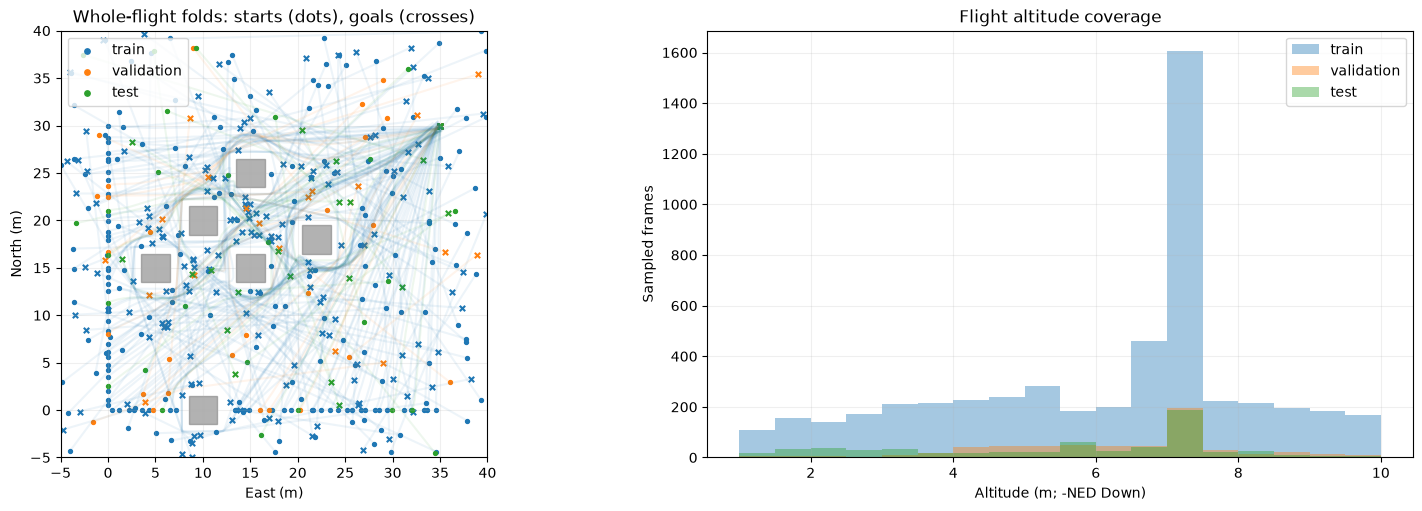

In [13]:
validate_config(CONFIG)
corpus = build_dataset(REPO_ROOT, CONFIG)
for name, info in corpus.diagnostics.items():
    print(f"{name}: {info['trajectory_count']} trajectories, {info['scan_count']} scans "
          f"({info['recorded_trajectories']} recorded / {info['synthetic_trajectories']} synthetic)")
assert all(set(corpus.splits[a]).isdisjoint(corpus.splits[b]) for a, b in
           (("train", "validation"), ("train", "test"), ("validation", "test")))
print("Corpus fingerprint:", corpus.source_metadata["fingerprint"])
plot_map_coverage(corpus, CONFIG)

### 6. Training function: the same mini-batches and cosine decay

AdamW, the range-weighted loss, mixed precision, epoch-wise cosine decay, checkpoints,
metric files, logging and plots follow the baseline. Frame batches are shuffled within
shuffled trajectories to bound disk I/O. Faults and pose/noise augmentations are regenerated
coherently per training flight and epoch. Validation stays fixed; only validation selects
the best checkpoint. Early stopping is explicitly configurable (disabled by default,
matching the baseline). Gradient clipping guards recurrent training.

At completion, the best checkpoint is evaluated once on held-out flights under assigned,
complete cold-start, long-blackout and repeated-burst profiles. Each report includes the
map-only baseline and separates recorded/synthetic data, full blackouts, cold starts, and
blackouts exceeding the history horizon. No mission-success or collision-safety claim is inferred.

In [14]:
# Shared checkpoint utilities are versioned with the cluster launcher.
sys.path.insert(0, str(DEFAULT_REPO_ROOT / "scripts" / "carc"))
from checkpoint_resume import (load_checkpoint as load_training_checkpoint,
    validate_resume as validate_training_resume, capture_rng as capture_training_rng,
    restore_rng as restore_training_rng, run_lock as training_run_lock, TrainingControl)

def make_loader(dataset, config, *, training=False, start_batch=0):
    t, r = config["training"], config["runtime"]
    options = dict(num_workers=0, pin_memory=r["pin_memory"] and r["device"] == "cuda")
    if training:
        batches = list(TrajectoryBatchSampler(dataset, t["batch_size"], config["run"]["seed"], pack=t.get("batch_policy", "trajectory") == "packed"))
        require(0 <= start_batch <= len(batches), "Checkpoint batch cursor exceeds epoch length.")
        # Skip only index lists, without reading or corrupting previous scan windows.
        return DataLoader(dataset, batch_sampler=batches[start_batch:], **options)
    return DataLoader(dataset, batch_size=t["batch_size"], shuffle=False, **options)


def loss_options(config):
    t = config["training"]
    return dict(max_range=MAX_RANGE, floor_m=t["weight_floor_range_m"], overestimate_weight=t["overestimate_weight"])


@torch.inference_mode()
def evaluate_reconstruction(model, dataset, config):
    """Report reconstruction AND map-only baseline, including true full-scan blackouts.

    Group metrics isolate source domain and information regime. A zero-sized
    subgroup reports null metrics rather than suggesting perfect performance.
    """
    device = next(model.parameters()).device
    model.eval()
    member = sector_membership(config["model"]).to(device)
    totals = {key: 0. for key in ("weighted", "weight", "sq", "abs", "n", "outage_sq", "outage_abs", "outage_n",
                                 "hit_abs", "hit_n", "sector_abs", "sector_n", "blackout_sq", "blackout_n")}
    groups = {}
    for batch in make_loader(dataset, config):
        batch = batch_to_device(batch, device)
        with autocast_context(config, device):
            prediction, prior = model(**model_inputs(batch), return_prior=True)
        target, valid, available = batch["target"], batch["target_valid"], batch["available"]
        error, lost = prediction.float()-target, ~available
        blackout = ~available.flatten(1).any(1)
        numerator, denominator = range_weighted_terms(prediction, target, valid, **loss_options(config))
        totals["weighted"] += numerator.item(); totals["weight"] += denominator.item()
        totals["sq"] += error.square().sum().item(); totals["abs"] += error.abs().sum().item(); totals["n"] += error.numel()
        totals["outage_sq"] += error.square()[lost].sum().item(); totals["outage_abs"] += error.abs()[lost].sum().item(); totals["outage_n"] += lost.sum().item()
        totals["hit_abs"] += error.abs()[valid].sum().item(); totals["hit_n"] += valid.sum().item()
        totals["blackout_sq"] += error[blackout].square().sum().item(); totals["blackout_n"] += error[blackout].numel()
        sector_error = sector_min_ranges(prediction, member, MAX_RANGE)-sector_min_ranges(target, member, MAX_RANGE)
        totals["sector_abs"] += sector_error.abs().sum().item(); totals["sector_n"] += sector_error.numel()
        regimes = {"all": torch.ones_like(blackout), "recorded": batch["source"] == 0,
                   "synthetic": batch["source"] == 1, "full_blackout": blackout,
                   "blackout_longer_than_history": blackout & (batch["ages"][:, -1] > config["data"]["history_steps"]*.1),
                   "cold_start": batch["present"].sum(1) == 1,
                   "cold_start_blackout": blackout & (batch["present"].sum(1) == 1)}
        for name, rows in regimes.items():
            group = groups.setdefault(name, dict(samples=0, beams=0, missing_beams=0, hidden_hit_beams=0,
                model_sq=0., model_abs=0., map_sq=0., map_abs=0., model_missing_sq=0., map_missing_sq=0.,
                model_dangerous=0, map_dangerous=0))
            group["samples"] += int(rows.sum().item())
            group["beams"] += error[rows].numel()
            hidden = lost[rows]
            hidden_hits = hidden & valid[rows]
            group["missing_beams"] += int(hidden.sum().item())
            group["hidden_hit_beams"] += int(hidden_hits.sum().item())
            for label, output in (("model", prediction), ("map", prior)):
                e = output[rows].float()-target[rows]
                group[f"{label}_sq"] += e.square().sum().item()
                group[f"{label}_abs"] += e.abs().sum().item()
                group[f"{label}_missing_sq"] += e.square()[hidden].sum().item()
                group[f"{label}_dangerous"] += int(((e > config["evaluation"]["dangerous_overestimate_m"]) & hidden_hits).sum().item())
    require(totals["n"] > 0, "Cannot evaluate an empty dataset.")
    # Validation selection requires a nonempty blackout subgroup; force profiles in small smoke fixtures.
    metrics = dict(val_loss=totals["weighted"]/totals["weight"], val_mse=totals["sq"]/totals["n"],
        val_rmse=math.sqrt(totals["sq"]/totals["n"]), val_mae=totals["abs"]/totals["n"],
        val_outage_mse=totals["outage_sq"]/max(totals["outage_n"], 1),
        val_outage_rmse=math.sqrt(totals["outage_sq"]/max(totals["outage_n"], 1)),
        val_outage_mae=totals["outage_abs"]/max(totals["outage_n"], 1),
        val_hit_mae=totals["hit_abs"]/max(totals["hit_n"], 1), val_sector_mae=totals["sector_abs"]/totals["sector_n"],
        val_blackout_mse=totals["blackout_sq"]/max(totals["blackout_n"], 1),
        val_blackout_rmse=math.sqrt(totals["blackout_sq"]/max(totals["blackout_n"], 1)))
    def ratio(numerator, denominator, *, root=False):
        return (math.sqrt(numerator/denominator) if root else numerator/denominator) if denominator else None
    report = {}
    for name, group in groups.items():
        report[name] = {key: group[key] for key in ("samples", "beams", "missing_beams", "hidden_hit_beams")}
        for label in ("model", "map"):
            report[name].update({f"{label}_rmse_m": ratio(group[f"{label}_sq"], group["beams"], root=True),
                f"{label}_mae_m": ratio(group[f"{label}_abs"], group["beams"]),
                f"{label}_missing_rmse_m": ratio(group[f"{label}_missing_sq"], group["missing_beams"], root=True),
                f"{label}_dangerous_overestimate_fraction": ratio(group[f"{label}_dangerous"], group["hidden_hit_beams"])})
    return metrics, report


def evaluate_holdout(model, test_data, config, run_dir):
    """Run once on the best-validation checkpoint; never select using test metrics."""
    report = {"scope": "held-out trajectories on the known static map; reconstruction, not mission safety",
              "pose_augmentation": config["augmentation"], "profiles": {}}
    for profile in config["evaluation"]["test_profiles"]:
        dataset = copy.copy(test_data)
        dataset.force_profile = None if profile == "assigned" else profile
        dataset.cache = OrderedDict()
        try:
            _, groups = evaluate_reconstruction(model, dataset, config)
            report["profiles"][profile] = dict(fault_manifest=dataset.fault_manifest(), groups=groups)
            print(f"Holdout {profile}: model RMSE={groups['all']['model_rmse_m']:.4f} m; map-only RMSE={groups['all']['map_rmse_m']:.4f} m", flush=True)
        finally:
            dataset.close()
    write_json(Path(run_dir)/"holdout_report.json", report)
    return report


def train_sparse_reconstruction(model, train_data, val_data, *, config, split_ids,
                                source_metadata, test_data=None, resume_checkpoint=None, control=None, batch_size_request=None):
    """Continue the original run; checkpoints commit completed optimizer batches."""
    config = copy.deepcopy(config)
    validate_config(config)
    saved = load_training_checkpoint(resume_checkpoint) if resume_checkpoint else None
    if saved is not None:
        validate_training_resume(saved, config, split_ids, source_metadata)
        run_dir = Path(resume_checkpoint).expanduser().resolve().parent
    else:
        stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
        run_dir = Path(config["paths"]["output_root"]).expanduser().resolve()/f'{config["run"]["name"]}_{stamp}'
        run_dir.mkdir(parents=True, exist_ok=False)
    with training_run_lock(run_dir):
        return _train_sparse_reconstruction_impl(model, train_data, val_data, config=config,
            split_ids=split_ids, source_metadata=source_metadata, test_data=test_data,
            saved=saved, run_dir=run_dir, control=control or TrainingControl(), batch_size_request=batch_size_request)


def _train_sparse_reconstruction_impl(model, train_data, val_data, *, config, split_ids,
                                     source_metadata, test_data, saved, run_dir, control, batch_size_request=None):
    import shutil
    m, t, r, s = (config[key] for key in ("model", "training", "runtime", "scheduler"))
    require(model.model_config == m, "Model architecture differs from the run configuration.")
    require(set(split_ids) == {"train", "validation", "test"}, "Supply all three whole-trajectory folds.")
    require(all(set(split_ids[a]).isdisjoint(split_ids[b]) for a, b in (("train", "validation"), ("train", "test"), ("validation", "test"))), "Trajectory leakage between folds.")
    for dataset, name in ((train_data, "train"), (val_data, "validation"), (test_data, "test")):
        if dataset is not None:
            require(dataset.split == name and [item["trajectory_id"] for item in dataset.records] == split_ids[name], "Dataset provenance differs from the frozen split.")
    require(source_metadata["split_policy"] == "whole_trajectory", "Source provenance must freeze whole-flight folds.")
    require(config["plots"]["scan_index"] < len(val_data), "plots.scan_index exceeds validation dataset.")
    require(any(val_data.profile(i) in ("cold_blackout", "long_blackout", "blackout_burst") for i in range(len(val_data.records))), "Validation must include guaranteed blackout profiles.")
    seed_training(config["run"]["seed"])
    device = runtime_device(config)
    if device.type == "cuda" and r["amp_dtype"] == "bf16":
        require(torch.cuda.is_bf16_supported(), "Saved BF16 run needs a BF16-capable GPU; request a compatible node.")
    model = model.to(device, dtype=torch.float32)
    torch.set_float32_matmul_precision(r["matmul_precision"])
    torch.backends.cudnn.benchmark = r["cudnn_benchmark"]
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda" and r["amp_dtype"] == "fp16")
    optimizer = torch.optim.AdamW(model.parameters(), lr=t["learning_rate"], weight_decay=t["weight_decay"],
        betas=tuple(t["betas"]), eps=t["eps"], fused=r["fused_adamw"] and device.type == "cuda")
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=s["t_max_epochs"], eta_min=s["min_lr"])
    logger = create_training_logger(run_dir/"training.log")
    keys = ("epoch", "train_loss", "val_loss", "train_mse", "val_mse", "train_rmse", "val_rmse",
            "val_mae", "val_outage_mse", "val_outage_rmse", "val_outage_mae", "val_hit_mae", "val_sector_mae",
            "val_blackout_mse", "val_blackout_rmse", "learning_rate", "next_learning_rate", "elapsed_s",
            "gpu_peak_allocated_mib", "stale_epochs", "improved")
    history = copy.deepcopy(saved["history"]) if saved else {key: [] for key in keys}
    require(set(history) == set(keys), "Saved metric schema differs from this training loop.")
    best_val = saved["best_val_metric"] if saved else float("inf")
    best_epoch = saved["best_epoch"] if saved else None
    stale_epochs = saved["stale_epochs"] if saved else 0
    completed_epoch = saved["epoch"] if saved else 0
    cursor = saved.get("resume_state", {}) if saved else {}
    first_epoch = completed_epoch+1
    best_weights = saved.get("best_model_state_dict") if saved else None
    pending_batch = copy.deepcopy(batch_size_request or (saved.get("pending_batch_size") if saved else None))
    batch_changes = copy.deepcopy(saved.get("batch_size_changes", [])) if saved else []
    if pending_batch:
        require(isinstance(pending_batch["batch_size"], int) and pending_batch["batch_size"] > 0
                and pending_batch.get("batch_policy", "packed") == "packed", "Invalid batch-size transition request.")
    metadata_path = run_dir/"summary.json"
    metadata = {}
    if saved and metadata_path.is_file():
        try:
            metadata = read_json(metadata_path)
        except (OSError, ValueError):
            metadata = {"recovered_summary_from_checkpoint": True}
    metadata.update(run_dir=str(run_dir), status="running", torch_version=str(torch.__version__), device=str(device),
        train_scans=len(train_data), validation_scans=len(val_data),
        trainable_parameters=sum(p.numel() for p in model.parameters()), selection_metric=t["selection_metric"],
        model_kind="known-map-temporal-sparse-range-reconstructor-v1", history_steps=config["data"]["history_steps"])
    metadata.setdefault("created_at_utc", datetime.now(timezone.utc).isoformat())
    metadata.update(source_metadata)
    metadata.pop("error", None); metadata.pop("error_type", None)
    last_save = perf_counter()
    latest_resume_state = dict(phase="epoch_end", epoch=first_epoch, next_batch=0)

    def snapshot(position):
        return dict(checkpoint_version=2, epoch=completed_epoch, resume_state=position,
            best_epoch=best_epoch, best_val_metric=best_val, selection_metric=t["selection_metric"],
            stale_epochs=stale_epochs, model_state_dict=model.state_dict(), best_model_state_dict=best_weights,
            optimizer_state_dict=optimizer.state_dict(), scheduler_state_dict=scheduler.state_dict(),
            scaler_state_dict=scaler.state_dict(), rng_state=capture_training_rng(),
            config=config, history=history, source_metadata=source_metadata, split_ids=split_ids,
            validation_fault_manifest=val_data.fault_manifest(),
            augmentation_epoch=position["epoch"], builder_version=DATA_BUILDER_VERSION,
            pending_batch_size=pending_batch, batch_size_changes=batch_changes)

    def commit(position):
        nonlocal last_save, latest_resume_state
        # Retain a second complete checkpoint before the atomic last.pt replacement.
        # A killed .tmp write never replaces either readable checkpoint.
        current = run_dir/"last.pt"
        if current.is_file():
            previous_tmp = run_dir/"last.prev.pt.tmp"
            shutil.copyfile(current, previous_tmp)
            os.replace(previous_tmp, run_dir/"last.prev.pt")
        payload = snapshot(position)
        save_checkpoint(current, payload)
        last_save, latest_resume_state = perf_counter(), copy.deepcopy(position)
        metadata.update(completed_epochs=completed_epoch, current_epoch=position["epoch"],
            next_batch=position["next_batch"], best_epoch=best_epoch,
            best_val_metric=best_val if math.isfinite(best_val) else None, checkpoint_version=2, batch_size=t["batch_size"],
            batch_policy=t.get("batch_policy", "trajectory"), pending_batch_size=pending_batch, batch_size_changes=batch_changes)
        write_json(metadata_path, metadata)
        return payload

    def stop(position):
        metadata.update(status="paused", stop_reason=getattr(control, "reason", None) or "requested stop")
        commit(position)
        logger.info("Saved continuation at epoch %d, next batch %d. Resume the same run directory.", position["epoch"], position["next_batch"])
        model.eval()
        return model, history, run_dir

    try:
        if saved:
            model.load_state_dict(saved["model_state_dict"], strict=True)
            # Scheduler is constructed before loading optimizer so its constructor
            # cannot replace the saved learning rate. Preserve the original horizon.
            optimizer.load_state_dict(saved["optimizer_state_dict"])
            if saved["optimizer_state_dict"]["state"]:
                # PyTorch's scheduler call-order flag is transient and is not in
                # optimizer.state_dict; these updates happened before the save.
                optimizer._opt_called = True
            scheduler.load_state_dict(saved["scheduler_state_dict"])
            scaler.load_state_dict(saved["scaler_state_dict"])
            if "validation_fault_manifest" in saved:
                require(saved["validation_fault_manifest"] == val_data.fault_manifest(), "Frozen validation fault timeline differs from checkpoint.")
            if best_weights is None and best_epoch is not None:
                if completed_epoch == best_epoch and not cursor.get("phase") == "train":
                    best_weights = {k: v.detach().cpu().clone() for k, v in saved["model_state_dict"].items()}
                else:
                    best = load_training_checkpoint(run_dir/"best.pt")
                    require(best["epoch"] == best_epoch, "Matching historical best.pt is missing; cannot reconstruct the saved best model.")
                    best_weights = best["model_state_dict"]
            metadata["resume_count"] = int(metadata.get("resume_count", 0))+1
            logger.info("Restoring completed epoch %d; next epoch %d, batch %d; LR %.9g.", completed_epoch, first_epoch,
                        cursor.get("next_batch", 0), optimizer.param_groups[0]["lr"])
            if "resume_state" not in saved:
                logger.info("Legacy checkpoint: continuing after the last completed epoch. Its unfinished epoch was not saved.")
        for filename, value in (("config.json", config), ("source.json", source_metadata), ("splits.json", split_ids),
                                ("summary.json", metadata), ("metrics.json", history),
                                ("validation_faults.json", val_data.fault_manifest())):
            write_json(run_dir/filename, value)
        # Checkpoint history is the transaction boundary. Rows written just before
        # a killed checkpoint save are rebuilt, so epochs are never duplicated.
        with (run_dir/"metrics.csv").open("w", newline="", encoding="utf-8") as stream:
            writer = csv.DictWriter(stream, fieldnames=keys)
            writer.writeheader()
            for i in range(completed_epoch):
                writer.writerow({key: history[key][i] for key in keys})
        if not saved:
            val_data.save_faults(run_dir/"validation_outages.npz")
        if saved:
            restore_training_rng(saved)
        # Commit before the first update: even a blackout during the first epoch
        # has a resumable starting point in new runs.
        if not saved:
            commit(latest_resume_state)
        already_early_stopped = bool(saved and t["early_stopping"] and stale_epochs >= t["patience"]
                                     and cursor.get("phase", "epoch_end") == "epoch_end")
        final_epoch = completed_epoch if already_early_stopped else t["epochs"]
        for epoch in range(first_epoch, final_epoch+1):
            start_time = perf_counter()
            if device.type == "cuda":
                torch.cuda.reset_peak_memory_stats(device)
            resuming_batch = bool(saved and epoch == first_epoch and cursor.get("phase") == "train")
            # Preserve the old batch cursor until its epoch is finished. At a
            # boundary Adam moments/LR/scaler stay intact; only grouping changes.
            if pending_batch and not (resuming_batch and cursor.get("next_batch", 0) > 0):
                previous = dict(batch_size=t["batch_size"], batch_policy=t.get("batch_policy", "trajectory"))
                t["batch_size"] = pending_batch["batch_size"]
                t["batch_policy"] = "packed"
                if previous != dict(batch_size=t["batch_size"], batch_policy="packed"):
                    change = dict(epoch=epoch, previous=previous, batch_size=t["batch_size"],
                                  batch_policy="packed", source=pending_batch.get("source", "saved request"),
                                  calibration_report=pending_batch.get("report"))
                    batch_changes.append(change)
                    logger.info("Batch transition at epoch %d: %d -> %d, packed across flights; optimizer and LR preserved.",
                                epoch, previous["batch_size"], t["batch_size"])
                pending_batch = None
                write_json(run_dir/"config.json", config)
                write_json(run_dir/"batch_size_changes.json", batch_changes)
                commit(dict(phase="epoch_end", epoch=epoch, next_batch=0))
            elif pending_batch:
                logger.info("Finishing saved epoch %d with batch size %d; requested batch %d starts next epoch.",
                            epoch, t["batch_size"], pending_batch["batch_size"])
            batch_start = cursor["next_batch"] if resuming_batch else 0
            accum = copy.deepcopy(cursor["accum"]) if resuming_batch else dict(weighted=0., weight=0., sq=0., elements=0)
            elapsed_before = cursor.get("elapsed_s", 0.) if resuming_batch else 0.
            train_data.set_epoch(epoch)
            write_json(run_dir/"training_faults_latest.json", train_data.fault_manifest())
            epoch_batches = len(TrajectoryBatchSampler(train_data, t["batch_size"], config["run"]["seed"], pack=t.get("batch_policy", "trajectory") == "packed"))
            loader = make_loader(train_data, config, training=True, start_batch=batch_start)
            lr_used = optimizer.param_groups[0]["lr"]
            model.train()
            for batch_index, batch in enumerate(loader, start=batch_start):
                if saved:
                    # DataLoader construction can consume torch RNG. Restore after
                    # its iterator is created, before the first continued forward.
                    restore_training_rng(saved)
                    saved = None
                position = dict(phase="train", epoch=epoch, next_batch=batch_index,
                                accum=accum, elapsed_s=elapsed_before+perf_counter()-start_time)
                if control.should_stop(stage="before_batch", epoch=epoch, next_batch=batch_index):
                    return stop(position)
                batch = batch_to_device(batch, device)
                optimizer.zero_grad(set_to_none=True)
                with autocast_context(config, device):
                    predictions = model(**model_inputs(batch))
                numerator, denominator = range_weighted_terms(predictions, batch["target"], batch["target_valid"], **loss_options(config))
                loss = numerator/denominator
                require(torch.isfinite(loss).item(), "Nonfinite training loss.")
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), t["gradient_clip_norm"], error_if_nonfinite=True)
                scaler.step(optimizer); scaler.update()
                accum["weighted"] += numerator.detach().item(); accum["weight"] += denominator.detach().item()
                accum["sq"] += (predictions.detach().float()-batch["target"]).square().sum().item()
                accum["elements"] += batch["target"].numel()
                position = dict(phase="train", epoch=epoch, next_batch=batch_index+1,
                                accum=accum, elapsed_s=elapsed_before+perf_counter()-start_time)
                if control.should_stop(stage="after_batch", epoch=epoch, next_batch=batch_index+1):
                    return stop(position)
                if perf_counter()-last_save >= control.checkpoint_seconds:
                    commit(position)
            if saved:  # Training completed before interruption; only validation remains.
                restore_training_rng(saved)
                saved = None
            position = dict(phase="train", epoch=epoch, next_batch=epoch_batches, accum=accum,
                            elapsed_s=elapsed_before+perf_counter()-start_time)
            commit(position)  # preserve every completed training pass before validation
            if control.should_stop(stage="before_validation", epoch=epoch, next_batch=epoch_batches):
                return stop(position)
            training_seconds = elapsed_before+perf_counter()-start_time
            validation_started = perf_counter()
            validation, baseline_report = evaluate_reconstruction(model, val_data, config)
            validation_seconds = perf_counter()-validation_started
            performance = dict(epoch=epoch, batch_size=t["batch_size"], batch_policy=t.get("batch_policy", "trajectory"),
                training_batches=epoch_batches, training_samples=accum["elements"]//(N_EL*N_AZ),
                training_seconds=training_seconds, validation_seconds=validation_seconds,
                training_samples_per_second=(accum["elements"]/(N_EL*N_AZ))/max(training_seconds, 1e-9),
                gpu_peak_allocated_gib=torch.cuda.max_memory_allocated(device)/2**30 if device.type == "cuda" else 0.,
                gpu_peak_reserved_gib=torch.cuda.max_memory_reserved(device)/2**30 if device.type == "cuda" else 0.)
            write_json(run_dir/"performance_latest.json", performance)
            logger.info("Batch=%d (%s) | training %.1fs | validation %.1fs | %.1f training samples/s | peak GPU reserved %.2f GiB",
                t["batch_size"], performance["batch_policy"], training_seconds, validation_seconds,
                performance["training_samples_per_second"], performance["gpu_peak_reserved_gib"])
            row = dict(epoch=epoch, train_loss=accum["weighted"]/accum["weight"], train_mse=accum["sq"]/accum["elements"],
                       train_rmse=math.sqrt(accum["sq"]/accum["elements"]), **validation)
            require(all(math.isfinite(v) and v >= 0 for v in row.values()), "Nonfinite/negative training metrics.")
            improved = row[t["selection_metric"]] < best_val
            if improved:
                best_val, best_epoch, stale_epochs = row[t["selection_metric"]], epoch, 0
                best_weights = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            else:
                stale_epochs += 1
            scheduler.step()
            row.update(learning_rate=lr_used, next_learning_rate=optimizer.param_groups[0]["lr"],
                elapsed_s=elapsed_before+perf_counter()-start_time,
                gpu_peak_allocated_mib=torch.cuda.max_memory_allocated(device)/2**20 if device.type == "cuda" else 0.,
                stale_epochs=stale_epochs, improved=improved)
            for key in keys:
                history[key].append(row[key])
            completed_epoch = epoch
            with (run_dir/"metrics.csv").open("a", newline="", encoding="utf-8") as stream:
                csv.DictWriter(stream, fieldnames=keys).writerow(row)
            write_json(run_dir/"metrics.json", history)
            payload = commit(dict(phase="epoch_end", epoch=epoch+1, next_batch=0))
            if improved:
                save_checkpoint(run_dir/"best.pt", payload)
                write_json(run_dir/"best_validation_report.json", baseline_report)
            if t["save_every_n_epochs"] and epoch % t["save_every_n_epochs"] == 0:
                save_checkpoint(run_dir/f"epoch_{epoch:04d}.pt", payload)
            log_epoch(logger, epoch=epoch, epochs=t["epochs"], row=row, selection_metric=t["selection_metric"],
                      improved=improved, stale_epochs=stale_epochs, patience=t["patience"])
            if control.should_stop(stage="epoch_end", epoch=epoch, next_batch=0):
                return stop(latest_resume_state)
            if t["early_stopping"] and stale_epochs >= t["patience"]:
                break
        if control.should_stop(stage="before_reports", epoch=completed_epoch, next_batch=0):
            return stop(latest_resume_state)
        require(best_weights is not None, "No completed validation epoch available for final reports.")
        model.load_state_dict(best_weights)
        model.eval()
        plot_run_history(run_dir, show=False)
        plot_validation_example(model, val_data, run_dir, show=False)
        if test_data is not None:
            evaluate_holdout(model, test_data, config, run_dir)
        best_row = {key: history[key][best_epoch-1] for key in keys}
        metadata.update(status="completed" if completed_epoch >= t["epochs"] else "early_stopped",
            completed_epochs=completed_epoch, best_epoch=best_epoch, best_val_metric=best_val,
            best_val_loss=best_row["val_loss"], best_val_rmse=best_row["val_rmse"],
            best_val_outage_rmse=best_row["val_outage_rmse"], best_val_blackout_rmse=best_row["val_blackout_rmse"])
        metadata.pop("stop_reason", None)
        write_json(metadata_path, metadata)
        return model, history, run_dir
    except BaseException as exc:
        logger.exception("Run failed; resume from the last complete checkpoint.")
        metadata.update(status="interrupted" if isinstance(exc, KeyboardInterrupt) else "failed",
            error_type=type(exc).__name__, error=str(exc), completed_epochs=completed_epoch)
        write_json(metadata_path, metadata)
        raise
    finally:
        for handler in list(logger.handlers):
            handler.close(); logger.removeHandler(handler)


### 7. Build causal train, validation and test datasets

This occupies the same preparation stage as the baseline's tensor builder. Full clean
scans stay on disk; batches expose the current scan and compact, strictly causal history.
Validation/test profiles and seeds are frozen. Windows never cross trajectory or split
boundaries. The first frame has one present step, with no fabricated past observations.

In [15]:
def fault_schedule(count, config, rng, profile):
    """Random repeated whole-scan bursts + spatial blocks + individual beam losses.

    No fixed n-outage assumption. Ages run over the whole trajectory, even when
    a blackout lasts longer than the model's finite history window.
    """
    k, m = config["masking"], config["model"]
    require(profile in k["evaluation_profiles"], f"Unknown fault profile: {profile}")
    azimuth = np.ones((count, N_AZ), bool)
    blackout = np.zeros(count, bool)
    if profile != "healthy":
        for t in range(count):
            if rng.random() < k["partial_probability"]:
                for _ in range(int(rng.integers(k["blocks_per_scan"][0], k["blocks_per_scan"][1]+1))):
                    distance = rng.uniform(*k["obstacle_distance_m"])
                    width = int(np.clip(round(np.degrees(2*np.arctan(m["obstacle_width_m"]/(2*distance)))/m["degree_per_column"]), 1, N_AZ))
                    start = int(rng.integers(N_AZ))
                    azimuth[t, (start+np.arange(width)) % N_AZ] = False
        if profile in ("mixed", "blackout_burst"):
            t = 0
            while t < count:
                if rng.random() < k["blackout_start_probability"]:
                    duration = int(rng.integers(k["blackout_duration_frames"][0], k["blackout_duration_frames"][1]+1))
                    blackout[t:min(t+duration, count)] = True
                    t += duration
                else:
                    t += 1
            if profile == "blackout_burst":
                # Guarantee at least one outage/recovery when the trajectory permits it.
                start = count//4
                duration = max(1, min(k["blackout_duration_frames"][1], max(1, count//3)))
                blackout[start:min(count-1, start+duration)] = True
                blackout[-1] = False
        elif profile == "cold_blackout":
            blackout[:] = True
        elif profile == "long_blackout":
            start = count//4
            blackout[start:min(count, start+max(k["long_blackout_frames"], count//2))] = True
    azimuth[blackout] = False
    availability = np.broadcast_to(azimuth[:, None], (count, N_EL, N_AZ)).copy()
    dropout = 0. if profile == "healthy" else float(rng.uniform(*k["beam_dropout_fraction"]))
    if dropout:
        availability &= rng.random(availability.shape) >= dropout
    ages = np.zeros(count, np.float32)
    for t in range(count):
        if not availability[t].any():
            ages[t] = (ages[t-1] if t else 0.)+config["data"]["sample_period_s"]
    return availability, ages


def augment_estimated_states(states, config, rng):
    a, dt = config["augmentation"], config["data"]["sample_period_s"]
    result = np.array(states, np.float32, copy=True)
    count = len(result)
    result[:, :3] += rng.normal(0, a["position_bias_std_m"], (1, 3))
    drift = rng.normal(0, a["position_drift_std_m_sqrt_s"]*math.sqrt(dt), (count, 3)).cumsum(0)
    result[:, :3] += drift+rng.normal(0, a["position_noise_std_m"], (count, 3))
    result[:, 3:6] += rng.normal(0, a["velocity_noise_std_mps"], (count, 3))
    result[:, 6:9] += np.deg2rad(rng.normal(0, a["attitude_bias_std_deg"], (1, 3)) +
                                     rng.normal(0, a["attitude_noise_std_deg"], (count, 3)))
    return result


class CausalTrajectoryDataset(Dataset):
    """One current full scan + <=H observed history steps, never crossing flights.

    Training regenerates a coherent fault/pose/noise timeline per flight/epoch.
    Overlapping windows see identical inputs at identical historical timestamps.
    Validation/test always use epoch=0 and fixed seeds. Only a few corrupted
    trajectories live in RAM; full clean labels stay in read-only memory maps.
    """
    def __init__(self, corpus, split, config, *, force_profile=None):
        self.config, self.split = copy.deepcopy(config), split
        self.force_profile = force_profile
        self.obstacles = np.asarray(corpus.scene["obstacles_ned_center_dimensions_m"], np.float32)
        lookup = {r["trajectory_id"]: r for r in corpus.records}
        self.records = [lookup[run_id] for run_id in corpus.splits[split]]
        self.offsets = np.r_[0, np.cumsum([r["count"] for r in self.records])]
        require(len(self.records) and self.offsets[-1] > 0, f"Empty dataset: {split}")
        self.cache, self.epoch = OrderedDict(), 0

    def __len__(self):
        return int(self.offsets[-1])

    def set_epoch(self, epoch):
        require(self.split == "train" or epoch == 0, "Validation/test augmentations must remain frozen.")
        self.epoch = int(epoch)
        self.close()

    @staticmethod
    def _close_trajectory(value):
        for key in ("target", "target_valid"):
            mapping = getattr(value[key], "_mmap", None)
            if mapping is not None:
                mapping.close()

    def close(self):
        """Release read-only mappings explicitly (also allows Windows cache cleanup)."""
        for value in self.cache.values():
            self._close_trajectory(value)
        self.cache.clear()

    def __enter__(self):
        return self

    def __exit__(self, *args):
        self.close()

    def trajectory_seed(self, ordinal):
        k = self.config["masking"]
        base = self.config["run"]["seed"] if self.split == "train" else k["validation_seed"] if self.split == "validation" else k["test_seed"]
        return stable_seed(base, self.split, self.records[ordinal]["trajectory_id"], self.epoch)

    def profile(self, ordinal):
        if self.force_profile:
            return self.force_profile
        k = self.config["masking"]
        if self.split == "train":
            rng = np.random.default_rng(stable_seed(self.trajectory_seed(ordinal), "profile"))
            return str(rng.choice(list(k["training_profiles"]), p=list(k["training_profiles"].values())))
        return k["evaluation_profiles"][ordinal % len(k["evaluation_profiles"])]

    def _load(self, ordinal):
        if ordinal in self.cache:
            self.cache.move_to_end(ordinal)
            return self.cache[ordinal]
        record, c = self.records[ordinal], self.config
        folder = Path(record["folder"])
        ranges, valid = np.load(folder/"ranges.npy", mmap_mode="r"), np.load(folder/"valid.npy", mmap_mode="r")
        with np.load(folder/"motion.npz", allow_pickle=False) as z:
            truth, goals, times = z["states"], z["goals"], z["times"]
        count = record["count"]
        require(truth.shape == (count, 9) and goals.shape == (count, 3) and times.shape == (count,)
                and np.isfinite(truth).all() and np.isfinite(goals).all()
                and np.allclose(np.diff(times), c["data"]["sample_period_s"], atol=1e-6, rtol=0), "Invalid cached motion arrays.")
        seed = self.trajectory_seed(ordinal)
        available, ages = fault_schedule(count, c, np.random.default_rng(stable_seed(seed, "fault")), self.profile(ordinal))
        states = augment_estimated_states(truth, c, np.random.default_rng(stable_seed(seed, "pose")))
        observed = np.where(available, ranges, 0.).astype(np.float32)
        observed_valid = valid & available
        noise = c["augmentation"]["measurement_noise_std_m"]
        if noise:
            perturbation = np.random.default_rng(stable_seed(seed, "measurement")).normal(0, noise, ranges.shape).astype(np.float32)
            observed = np.where(observed_valid, np.clip(observed+perturbation, 1e-4, MAX_RANGE), observed)
        history = pool_observed_history(observed, observed_valid, available, c["model"])
        reset_rng = np.random.default_rng(stable_seed(seed, "history_reset"))
        resets = reset_rng.random(count) < (c["masking"]["history_reset_probability"] if self.split == "train" else 0.)
        value = dict(target=ranges, target_valid=valid, ranges=observed, valid=observed_valid,
                     available=available, states=states, goals=goals, history=history, ages=ages, resets=resets)
        self.cache[ordinal] = value
        while len(self.cache) > c["data"]["cache_trajectories"]:
            _, evicted = self.cache.popitem(last=False)
            self._close_trajectory(evicted)
        return value

    def __getitem__(self, index):
        require(isinstance(index, (int, np.integer)) and 0 <= index < len(self), "Sample index is outside the dataset.")
        ordinal = int(np.searchsorted(self.offsets, index, side="right")-1)
        t, horizon = int(index-self.offsets[ordinal]), self.config["data"]["history_steps"]
        trajectory = self._load(ordinal)
        start = max(0, t-horizon+1)
        # A reset truncates past history; it never introduces future observations.
        reset_indices = np.flatnonzero(trajectory["resets"][start:t+1])
        if len(reset_indices):
            start += int(reset_indices[-1])
        length, destination = t-start+1, slice(horizon-(t-start+1), horizon)
        item = {key: np.array(trajectory[key][t], copy=True) for key in
                ("target", "target_valid", "ranges", "valid", "available")}
        for key in ("states", "goals", "history", "ages"):
            item[key] = np.zeros((horizon, *trajectory[key].shape[1:]), np.float32)
            item[key][destination] = trajectory[key][start:t+1]
        item["present"] = np.zeros(horizon, bool)
        item["present"][destination] = True
        item["obstacles"] = self.obstacles.copy()
        item["source"] = np.asarray(self.records[ordinal]["source"] == "synthetic", np.int64)
        item["trajectory_index"], item["timestep"] = np.asarray(ordinal), np.asarray(t)
        return {key: torch.from_numpy(value) for key, value in item.items()}

    def fault_manifest(self):
        return {"split": self.split, "epoch": self.epoch, "force_profile": self.force_profile,
                "history_steps": self.config["data"]["history_steps"],
                "trajectory_profiles": [dict(trajectory_id=r["trajectory_id"], seed=self.trajectory_seed(i),
                                              profile=self.profile(i), count=r["count"]) for i, r in enumerate(self.records)]}

    def save_faults(self, path):
        """Compressed full timelines, not overlapping window copies; IDs align each array."""
        arrays = {}
        for i, record in enumerate(self.records):
            trajectory = self._load(i)
            arrays[f"available_{i:04d}"] = trajectory["available"]
            arrays[f"ages_{i:04d}"] = trajectory["ages"]
        arrays["manifest_json"] = np.asarray(json.dumps(self.fault_manifest()))
        np.savez_compressed(path, **arrays)
        self.close()


class TrajectoryBatchSampler:
    """Shuffle trajectories and frame batches, with bounded I/O and RAM.

    Fully random frames across hundreds of trajectories would decompress/regenerate
    a whole corrupted flight for nearly every sample. Group batches by trajectory;
    shuffle all frame indices inside each trajectory every epoch instead.
    """
    def __init__(self, dataset, batch_size, seed, pack=False):
        self.dataset, self.batch_size, self.seed = dataset, batch_size, seed
        self.pack = pack

    def __len__(self):
        if self.pack:
            return math.ceil(len(self.dataset)/self.batch_size)
        return sum(math.ceil(r["count"]/self.batch_size) for r in self.dataset.records)

    def __iter__(self):
        rng = np.random.default_rng(stable_seed(self.seed, self.dataset.epoch, "batches"))
        pending = []
        for ordinal in rng.permutation(len(self.dataset.records)):
            start, stop = self.dataset.offsets[ordinal:ordinal+2]
            indices = rng.permutation(np.arange(start, stop))
            if self.pack:
                indices = pending + indices.tolist()
                stop = (len(indices)//self.batch_size)*self.batch_size
                for batch_start in range(0, stop, self.batch_size):
                    yield indices[batch_start:batch_start+self.batch_size]
                pending = indices[stop:]
            else:
                for batch_start in range(0, len(indices), self.batch_size):
                    yield indices[batch_start:batch_start+self.batch_size].tolist()
        if self.pack and pending:
            yield pending


def build_train_val_tensors(corpus, config):
    """Keep the baseline's preparation stage, now backed by lazy causal datasets."""
    return (CausalTrajectoryDataset(corpus, "train", config),
            CausalTrajectoryDataset(corpus, "validation", config),
            CausalTrajectoryDataset(corpus, "test", config))

### 8. Train and save a new map-wide temporal run

Run the next two cells when ready. The first prepares lazy datasets and prints their shapes;
the second starts training. The seed is applied before model construction. Every run has
a separate folder, complete source/split provenance, checkpoints and holdout comparisons.
The original notebook, raw flights and existing single-episode weights remain unchanged.
For a new CARC allocation after interruption, run
`python -u scripts/carc/resume_map_temporal.py`. It continues the newest saved run
in the same results folder. Existing checkpoints resume at their saved epoch;
new checkpoints also preserve the next batch within an epoch. See
`docs/CARC_MAP_TEMPORAL.md` for explicit run selection and timing controls.


In [16]:
train_dataset, val_dataset, test_dataset = build_train_val_tensors(corpus, CONFIG)
for name, dataset in (("Train", train_dataset), ("Validation", val_dataset), ("Test", test_dataset)):
    sample = dataset[0]
    print(name, "samples:", len(dataset), "| state history:", tuple(sample["states"].shape),
          "| observed history:", tuple(sample["history"].shape), "| target:", tuple(sample["target"].shape))
    assert int(sample["present"].sum()) == 1
print("Validation profiles:", [val_dataset.profile(i) for i in range(len(val_dataset.records))])
print("No training has started. Run the next cell to fit the model.")

Train samples: 51009 | state history: (16, 9) | observed history: (16, 3, 3, 90) | target: (15, 716)
Validation samples: 5880 | state history: (16, 9) | observed history: (16, 3, 3, 90) | target: (15, 716)
Test samples: 6082 | state history: (16, 9) | observed history: (16, 3, 3, 90) | target: (15, 716)
Validation profiles: ['healthy', 'mixed', 'blackout_burst', 'cold_blackout', 'long_blackout', 'healthy', 'mixed', 'blackout_burst', 'cold_blackout', 'long_blackout', 'healthy', 'mixed', 'blackout_burst', 'cold_blackout', 'long_blackout', 'healthy', 'mixed', 'blackout_burst', 'cold_blackout', 'long_blackout', 'healthy', 'mixed', 'blackout_burst', 'cold_blackout', 'long_blackout', 'healthy', 'mixed']
No training has started. Run the next cell to fit the model.


In [17]:
validate_config(CONFIG)
seed_training(CONFIG["run"]["seed"])
model, history, run_dir = train_sparse_reconstruction(
    SparseRangeReconstructor(CONFIG["model"], CONFIG["data"]["sample_period_s"]),
    train_dataset, val_dataset, test_data=test_dataset,
    config=CONFIG, split_ids=corpus.splits, source_metadata=corpus.source_metadata,
    resume_checkpoint=globals().get("RESUME_CHECKPOINT"),
    control=globals().get("TRAINING_CONTROL"),
    batch_size_request=globals().get("BATCH_SIZE_REQUEST"),
)
print("Run saved to:", run_dir)
TRAINING_PAUSED = json.loads((Path(run_dir)/"summary.json").read_text(encoding="utf-8"))["status"] == "paused"


00:51:59 | INFO | Run output: A:\Projects\ARES\results\sparse_reconstruction_map_temporal\Map Temporal Sparsity Invariant CNN_20261118T085154_845800Z
01:06:46 | INFO | epoch=0001/1000 | train_loss=0.20738 | val_loss=0.07381 | val_rmse=0.1963 | outage_rmse=0.2487 | outage_mae=0.0355 | sector_mae=0.0343 | lr=1.00e-03 | 886.8s | BEST (val_loss)
01:06:46 | INFO | full-blackout RMSE=0.2535 m | map-only RMSE=0.2384 m
01:14:01 | ERROR | Run failed/interrupted; completed epoch checkpoints are retained.
Traceback (most recent call last):
  File "C:\Users\athar\AppData\Local\Temp\ipykernel_11396\2792418461.py", line 169, in train_sparse_reconstruction
    predictions = model(**model_inputs(batch))
                  ^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "a:\Projects\ARES\.venv\Lib\site-packages\torch\nn\modules\module.py", line 1779, in _wrapped_call_impl
    return self._call_impl(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "a:\Projects\ARES\.venv\Lib\site-packages\torch\nn

KeyboardInterrupt: 

### 9. Visualize saved results

The loss/learning-rate plots and validation scan comparison use the saved best-validation
model. `holdout_report.json` contains the final unseen-flight comparisons with the map-only
baseline; a lower training loss does not establish robustness. Inspect full-blackout and
recorded-flight groups before deciding whether more MATLAB collection is needed.

For later per-UAV inference, construct `runtime = MultiUavReconstruction(model, CONFIG)`
and call `runtime.step(uav_id, timestamp_s, ranges, valid, available, state9, goal3, boxes_Ox6)`
at each scan time. Use the same NED/sensor conventions as training, and reset that UAV's
buffer at every mission start. Share weights, never histories. This notebook does not
modify the MATLAB simulation or export a deployable Simulink model.

In [ ]:
if not globals().get("TRAINING_PAUSED", False):
    plot_run_history(run_dir, show=True)


In [ ]:
if not globals().get("TRAINING_PAUSED", False):
    plot_validation_example(model, val_dataset, run_dir, show=True)
    holdout = json.loads((Path(run_dir) / "holdout_report.json").read_text(encoding="utf-8"))
    for profile, report in holdout["profiles"].items():
        for group_name in ("all", "recorded", "synthetic", "full_blackout", "cold_start_blackout", "blackout_longer_than_history"):
            group = report["groups"][group_name]
            print(profile, group_name, "samples=", group["samples"],
                  "model RMSE (m)=", group["model_rmse_m"], "map-only RMSE (m)=", group["map_rmse_m"])
